

# Full Improved ISO 20022 Anomaly-Detection Study

## Self-Supervised Masked Tabular Transformer with a Strong Controlled-Anomaly Reference

**Research question:** *Can self-supervised models identify meaningful anomalies in ISO 20022 payment transactions when reliable anomaly labels are unavailable?*

This complete notebook keeps the masked tabular Transformer (MTT), all classical baselines, reconstruction analysis, statistical inference, ablations, explanations and exports. It also repairs the main weaknesses in the earlier version:

- CTGAN is removed from the headline model because ten generated normal rows per real row changed the final training distribution after hyperparameter selection;
- every final deep model is trained on real development-normal traffic only;
- controlled anomalies change raw ISO fields and then recompute derived fields, so no impossible derived-field shortcut is created;
- a self-supervised Extra Trees reference is trained on controlled corruptions, tuned on a separate controlled TUNE set, and tested on an independent controlled lockbox;
- `TxSts` remains a separate external proxy endpoint and is never used to tune the self-supervised models;
- all cells are ordered so `BEST_BASE` is created before the classical baselines are fitted.

### Validated reference result


The currency-shuffle null-control AUROC was **0.496**, correctly close to chance. These results measure controlled structural-anomaly detection. They are not a claim that the same model predicts real fraud or `RJCT` at those levels.


## Notes on this revision (response to Recommendations memo)

This notebook was previously run only in `PRESET = "standard"` mode (10 HPO trials), and the
frozen MTT (mask ratio 0.40, AUPRC ≈ 0.0644) did not beat the tuned Isolation Forest baseline
(AUPRC ≈ 0.0714). The Recommendations memo noted a post-hoc ablation at mask ratio 0.65
reached AUPRC ≈ 0.0835 on the TEST set, and proposed an "MTT V4" spec (§3) to test whether
the MTT is under-tuned rather than incapable.

**Changes made in this revision, scoped to what is safely automatable without a full pipeline
rewrite:**

1. **§1 / §8 — run in `full` mode.** `PRESET` switched from `"standard"` to `"full"`, and
   `hpo_trials` for `full` raised from 20 to 60 (within the memo's recommended 50–75 range).
   This only searches development data (FIT/TUNE + pseudo-anomalies); `TxSts` is never used for
   HPO, matching §4/§5 of the memo.
2. **§2.1 — widen the masking-ratio search.** The Optuna mask-ratio range in `mtt_hpo`
   changed from 0.15–0.60 to 0.25–0.75 (step 0.05), which explicitly covers 0.60, 0.65, 0.70
   and 0.75.
3. **§2.2 — normalise categorical reconstruction losses.** `MixedReconstructor.feature_losses`
   now divides each categorical field's cross-entropy by `log(cardinality)`, so high-cardinality
   fields (e.g. BICs) no longer structurally dominate the masked-reconstruction objective. This
   changes the training signal, the LOO loss matrix, and therefore every downstream
   reconstruction-based score.

**Deferred items (§2.3–2.8, §3 V4 spec) — not implemented in this pass:** normal-only
learnability weighting, the dual masked+replaced-feature relational objective,
Optuna-learned semantic score weights, the expanded backward-looking velocity/frequency
feature set, and conditional-vs-marginal surprise scoring. Each is a non-trivial addition to
`iso_v3_data.py` / `iso_v3_models.py` / `iso_v3_eval.py` (new features, a second pretext task,
a constrained simplex search) and is left as follow-up work rather than being rushed in
alongside the changes above.

**§6 — validation caveat carries over unchanged.** The mask-ratio range above was widened
*because* 0.65 looked promising on the already-viewed TEST set. Whatever the search now picks
is therefore still evaluated against a TEST set that has already informed model design â€” **any
improvement produced by this revision is exploratory / post-hoc, not confirmatory**, exactly as
§6 of the memo describes. The result below should not be reported as a clean win over the
Isolation Forest baseline without an independent Dataset B confirmatory run. §5's "do not
promote a TEST-set-selected result to the final model" rule still applies to whatever mask
ratio this HPO run selects.


## Revision v5 — what changed and why (read this first)

**Diagnosis of the v4 run.** (1) `TxSts` (RJCT) is statistically independent of every ex-ante field in this corpus (gradient-boosted probe AUROC ≈ 0.50; per-field chi-square tests non-significant), so every model scores at chance on it — that is a property of the data, not evidence about the MTT. (2) The run stopped inside the ablation ladder (no outputs after section 14), so the **controlled benchmark — the only endpoint that can answer the research question — never executed**. The log also shows `Device: cpu`.

**Changes in v5** (all clearly marked, nothing else touched):
1. `RUN_ABLATIONS=False` by default; the controlled benchmark is now **section 8b**, run right after the baselines.
2. **Section 8a / `ReconScoreModel.fit_field_weights`, methods `learn_max`, `learn_sum`:** drop fields that cannot separate anomalies from normals (currency, purpose, time-of-day, cents, velocity are independent noise here). Weights come from a controlled set built on REF normals with the A6 null family excluded, frozen before the lockbox.
3. **`loo_loss_matrix(..., blocks=...)` + `twin_blocks`:** optional joint masking of country/BIC-country twins, evaluated as an extra variant (scoring only — no retraining).
4. Controlled benchmark now reports the MTT variants, LOF/IF/etc., the supervised-on-corruptions Extra Trees reference, per-family AUROC and paired bootstrap ΔAUPRC.
5. All outputs were cleared: none of the v4 numbers correspond to this code.

**Caveats.** The learned weights use the same *kinds* of corruption as the lockbox (different seeds and rows), so gains from `learn_*` are partly "knowing which fields matter for these families" — report them as such. This is exploratory, not confirmatory, and controlled-anomaly performance is not evidence of real-fraud performance. The v5 code paths were smoke-tested end-to-end on CPU only; results from the full preset have not been produced by the author of this revision.

## 0. Configuration and reproducibility

Use **T4 GPU** in Colab (`Runtime → Change runtime type → T4 GPU`). `standard` is the recommended dissertation run. `smoke` validates the notebook quickly; `full` increases HPO and inference resampling for the paper archive.


In [ ]:
#@title Configuration { display-mode: "form" }
PRESET = "full"  #@param ["smoke", "standard", "full"]  # switched from "standard" per Recommendations §1: standard-mode findings did not support the claim
CSV_PATH = "iso20022_analytics.csv"  #@param {type:"string"}
SEEDS = [42, 2026]
ALPHA_FPR = 0.05  # conformal false-alert target on accepted calibration traffic
RUN_ABLATIONS = False  # v5: OFF by default. The 12-arm ladder retrains 6 extra models x 2 seeds and is what stopped the v4 run before the controlled benchmark. Turn on only AFTER the controlled benchmark (section 8b) has finished.
RUN_CONTROLLED_BENCHMARK = True
RUN_SELF_SUPERVISED_REFERENCE = True
USE_CTGAN = False

PRESETS = {
    "smoke":    dict(hpo_trials=2, hpo_epochs=5,  final_epochs=6,  dae_epochs=2,  ablation_epochs=3,  n_boot=100,  n_perm=100,  pseudo_fraction=.30),
    "standard": dict(hpo_trials=10,hpo_epochs=30, final_epochs=60, dae_epochs=40, ablation_epochs=25, n_boot=1000, n_perm=2000, pseudo_fraction=1.00),
    "full":     dict(hpo_trials=60,hpo_epochs=45, final_epochs=90, dae_epochs=60, ablation_epochs=40, n_boot=3000, n_perm=5000,pseudo_fraction=1.00),  # hpo_trials raised 20->60 per Recommendations §2.1 (target 50-75 trials)
}
CFG = PRESETS[PRESET]
CFG.update(csv_path=CSV_PATH, seeds=SEEDS, alpha_fpr=ALPHA_FPR, preset=PRESET)
print(CFG)


{'hpo_trials': 60, 'hpo_epochs': 45, 'final_epochs': 90, 'dae_epochs': 60, 'ablation_epochs': 40, 'n_boot': 3000, 'n_perm': 5000, 'pseudo_fraction': 1.0, 'csv_path': 'iso20022_analytics.csv', 'seeds': [42, 2026], 'alpha_fpr': 0.05, 'preset': 'full'}


In [ ]:
#@title Imports, device, seeds and publication-output helpers
import os, sys, json, time, math, random, hashlib, platform, warnings, zipfile, subprocess
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Markdown
import torch, sklearn, scipy, statsmodels
warnings.filterwarnings("ignore")

try:
    import optuna
except Exception:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "optuna"])
    import optuna

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE, "| torch", torch.__version__, "| sklearn", sklearn.__version__)

OUT = Path("outputs_v3"); TABLE_DIR=OUT/"tables"; FIG_DIR=OUT/"figures"; MODEL_DIR=OUT/"models"
for d in [OUT,TABLE_DIR,FIG_DIR,MODEL_DIR]: d.mkdir(parents=True,exist_ok=True)
TABLES={}; FIGURES={}

def seed_all(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)

def show_table(df, key, caption, max_rows=30):
    df2=df.copy(); TABLES[key]=(df2,caption); df2.to_csv(TABLE_DIR/f"{key}.csv",index=True)
    try: (TABLE_DIR/f"{key}.tex").write_text(df2.to_latex(index=True,escape=True,float_format=lambda x:f"{x:.4f}"))
    except Exception: pass
    display(Markdown(f"**{caption}**")); display(df2.head(max_rows))

def show_figure(fig,key,caption):
    FIGURES[key]=caption; fig.savefig(FIG_DIR/f"{key}.png",dpi=180,bbox_inches="tight"); fig.savefig(FIG_DIR/f"{key}.pdf",bbox_inches="tight")
    display(Markdown(f"**{caption}**")); plt.show()

seed_all(SEEDS[0])


Device: cpu | torch 2.11.0+cpu | sklearn 1.6.1


In [ ]:
#@title Load the dataset (upload prompt if needed)
if not os.path.exists(CSV_PATH):
    try:
        from google.colab import files
        print("Upload iso20022_analytic.csv")
        up=files.upload()
        if CSV_PATH not in up and up:
            first=next(iter(up)); os.rename(first,CSV_PATH)
    except Exception as e:
        raise FileNotFoundError(f"Cannot find {CSV_PATH}. Upload it to the Colab session.") from e
print("Found",CSV_PATH,os.path.getsize(CSV_PATH),"bytes")


Found iso20022_analytics.csv 686286 bytes


## 1. Reusable pipeline modules

The implementation is split into importable modules so that modelling decisions are explicit and auditable. All modules are written into the Colab runtime by the next cells.


In [ ]:
%%writefile iso_v3_data.py
from __future__ import annotations
import hashlib, numpy as np, pandas as pd

ISO20022_SCHEMA = [
    ("MessageId","GrpHdr/MsgId","pacs.008","ex-ante","identifier"),
    ("EndToEndId","CdtTrfTxInf/PmtId/EndToEndId","pacs.008","ex-ante","identifier"),
    ("TxDateTime","GrpHdr/CreDtTm","pacs.008","ex-ante","temporal"),
    ("IntrBkSttlmDt","CdtTrfTxInf/IntrBkSttlmDt","pacs.008","ex-ante","temporal"),
    ("InstdAmt","CdtTrfTxInf/InstdAmt","pacs.008","ex-ante","numeric"),
    ("Currency","CdtTrfTxInf/InstdAmt/@Ccy","pacs.008","ex-ante","categorical"),
    ("DbtrAgtBIC","CdtTrfTxInf/DbtrAgt/FinInstnId/BICFI","pacs.008","ex-ante","categorical"),
    ("CdtrAgtBIC","CdtTrfTxInf/CdtrAgt/FinInstnId/BICFI","pacs.008","ex-ante","categorical"),
    ("DbtrCountry","CdtTrfTxInf/Dbtr/PstlAdr/Ctry","pacs.008","ex-ante","categorical"),
    ("CdtrCountry","CdtTrfTxInf/Cdtr/PstlAdr/Ctry","pacs.008","ex-ante","categorical"),
    ("PurposeCode","CdtTrfTxInf/Purp/Cd","pacs.008","ex-ante","categorical"),
    ("TxSts","TxInfAndSts/TxSts","pacs.002","EX-POST","proxy outcome"),
    ("StatusTimestamp","GrpHdr/CreDtTm (status report)","pacs.002","EX-POST","outcome timestamp"),
    ("RejectionReason","TxInfAndSts/StsRsnInf/Rsn/Cd","pacs.002","EX-POST","proxy outcome detail"),
    ("ProcessingTimeSecs","derived: pacs.002 timestamp - pacs.008 timestamp","derived","EX-POST","outcome-adjacent"),
]
EX_POST_FIELDS = ["TxSts","StatusTimestamp","RejectionReason","ProcessingTimeSecs"]
IDENTIFIERS = ["MessageId","EndToEndId"]
RAW_CATEGORICAL = ["Currency","DbtrAgtBIC","CdtrAgtBIC","DbtrCountry","CdtrCountry","PurposeCode"]

NUMERIC_FEATURES = [
    "log_amount","amt_cents","hour_sin","hour_cos","dow_sin","dow_cos","is_weekend",
    "settle_lag_days","vel_agentpair_60s","vel_sameamt_300s"
]
CATEGORICAL_FEATURES = RAW_CATEGORICAL + ["dbtr_bic_ctry","cdtr_bic_ctry"]

# Equal-weight semantic domains for the proposal-faithful reconstruction score.
SEMANTIC_GROUPS = {
    "value": ["log_amount","amt_cents","Currency"],
    "routing": ["DbtrAgtBIC","CdtrAgtBIC","DbtrCountry","CdtrCountry","dbtr_bic_ctry","cdtr_bic_ctry"],
    "purpose": ["PurposeCode"],
    "temporal": ["hour_sin","hour_cos","dow_sin","dow_cos","is_weekend","settle_lag_days"],
    "velocity": ["vel_agentpair_60s","vel_sameamt_300s"],
}

def schema_table():
    return pd.DataFrame(ISO20022_SCHEMA, columns=["Column","ISO 20022 element","Message","Availability","Role"])

def load_raw(path: str) -> pd.DataFrame:
    df = pd.read_csv(path)
    for c in ["TxDateTime","StatusTimestamp","IntrBkSttlmDt"]:
        df[c] = pd.to_datetime(df[c], errors="raise")
    return df.sort_values("TxDateTime", kind="mergesort").reset_index(drop=True)

def file_sha256(path: str) -> str:
    h=hashlib.sha256()
    with open(path,"rb") as f:
        for b in iter(lambda:f.read(1<<20), b""): h.update(b)
    return h.hexdigest()

def verify_leakage_identity(df):
    delta=(df["StatusTimestamp"]-df["TxDateTime"]).dt.total_seconds().to_numpy(float)
    p=df["ProcessingTimeSecs"].to_numpy(float)
    return {"n_checked":len(df),"identity_holds":bool(np.allclose(delta,p)),
            "max_abs_deviation_secs":float(np.max(np.abs(delta-p)))}

def _window_count(ts: np.ndarray, key: np.ndarray, window_s: int) -> np.ndarray:
    order=np.argsort(ts,kind="mergesort"); out=np.zeros(len(ts),float); seen={}
    for i in order:
        k=key[i]; t=int(ts[i]); buf=seen.setdefault(k,[])
        while buf and buf[0] < t-window_s: buf.pop(0)
        out[i]=len(buf); buf.append(t)
    return out

def build_ex_ante_frame(df: pd.DataFrame) -> pd.DataFrame:
    """Row-local / backward-looking features only. No pacs.002/status fields."""
    f=pd.DataFrame(index=df.index)
    amt=df["InstdAmt"].astype(float).to_numpy()
    f["log_amount"]=np.log1p(np.clip(amt,0,None))
    f["amt_cents"]=np.round((amt*100)%100).astype(float)
    t=df["TxDateTime"]
    hour=t.dt.hour.to_numpy()+t.dt.minute.to_numpy()/60+t.dt.second.to_numpy()/3600
    dow=t.dt.dayofweek.to_numpy()
    f["hour_sin"]=np.sin(2*np.pi*hour/24); f["hour_cos"]=np.cos(2*np.pi*hour/24)
    f["dow_sin"]=np.sin(2*np.pi*dow/7); f["dow_cos"]=np.cos(2*np.pi*dow/7)
    f["is_weekend"]=(dow>=5).astype(float)
    f["settle_lag_days"]=(df["IntrBkSttlmDt"].dt.normalize()-t.dt.normalize()).dt.days.astype(float)
    f["dbtr_bic_ctry"]=df["DbtrAgtBIC"].astype(str).str[4:6]
    f["cdtr_bic_ctry"]=df["CdtrAgtBIC"].astype(str).str[4:6]
    ts=(t.astype("int64")//10**9).to_numpy()
    pair=(df["DbtrAgtBIC"].astype(str)+"|"+df["CdtrAgtBIC"].astype(str)).to_numpy()
    f["vel_agentpair_60s"]=_window_count(ts,pair,60)
    amtkey=np.round(amt,0).astype(np.int64).astype(str)
    f["vel_sameamt_300s"]=_window_count(ts,np.char.add(pair.astype(str),amtkey),300)
    for c in RAW_CATEGORICAL: f[c]=df[c].astype(str).to_numpy()
    return f

def chronological_split(df, fractions=(0.50,0.10,0.10,0.10,0.20)):
    names=["FIT","TUNE","REF","CAL","TEST"]; n=len(df)
    cuts=np.cumsum([0]+list(fractions)); out={}
    for i,name in enumerate(names):
        a=int(round(cuts[i]*n)); b=int(round(cuts[i+1]*n)) if i<len(names)-1 else n
        out[name]=np.arange(a,b,dtype=int)
    return out

class FitOnTrain:
    """Robust numeric scaling + train-only categorical vocabularies (0=OOV)."""
    def __init__(self,min_freq=2):
        self.min_freq=min_freq; self.cat_maps={}; self.cat_sizes={}; self.center_=None; self.scale_=None
    def fit(self,f):
        for c in CATEGORICAL_FEATURES:
            vc=f[c].astype(str).value_counts(); keep=sorted(vc[vc>=self.min_freq].index.tolist())
            self.cat_maps[c]={v:i+1 for i,v in enumerate(keep)}; self.cat_sizes[c]=len(keep)+1
        X=f[NUMERIC_FEATURES].to_numpy(float)
        med=np.nanmedian(X,axis=0); q75=np.nanpercentile(X,75,axis=0); q25=np.nanpercentile(X,25,axis=0)
        sc=q75-q25; sc[~np.isfinite(sc)|(sc<1e-8)]=1.0
        self.center_=med; self.scale_=sc; return self
    def transform(self,f):
        xn=(f[NUMERIC_FEATURES].to_numpy(float)-self.center_)/self.scale_
        xn=np.nan_to_num(xn,nan=0,posinf=12,neginf=-12); xn=np.clip(xn,-12,12).astype(np.float32)
        xc=np.column_stack([f[c].astype(str).map(self.cat_maps[c]).fillna(0).to_numpy(np.int64)
                            for c in CATEGORICAL_FEATURES]).astype(np.int64)
        return xn,xc
    def fit_transform(self,f): return self.fit(f).transform(f)
    def inverse_numeric(self,xn): return xn*self.scale_+self.center_
    def feature_names(self): return NUMERIC_FEATURES+CATEGORICAL_FEATURES
    def group_indices(self):
        names=self.feature_names(); idx={n:i for i,n in enumerate(names)}
        return {g:[idx[n] for n in cols if n in idx] for g,cols in SEMANTIC_GROUPS.items()}

def cramers_v(a,b):
    tab=pd.crosstab(pd.Series(a),pd.Series(b)); n=tab.values.sum()
    if n==0 or min(tab.shape)<2: return np.nan
    from scipy.stats import chi2_contingency
    chi2=chi2_contingency(tab,correction=False)[0]; phi2=chi2/n; r,k=tab.shape
    phi2corr=max(0,phi2-(k-1)*(r-1)/(n-1)); rcorr=r-(r-1)**2/(n-1); kcorr=k-(k-1)**2/(n-1)
    den=max(1e-12,min(kcorr-1,rcorr-1)); return float(np.sqrt(phi2corr/den))

def dependency_audit(f_train: pd.DataFrame):
    cats=CATEGORICAL_FEATURES; rows=[]
    for i,a in enumerate(cats):
        for b in cats[i+1:]: rows.append({"Feature A":a,"Feature B":b,"Cramers_V":cramers_v(f_train[a],f_train[b])})
    return pd.DataFrame(rows).sort_values("Cramers_V",ascending=False).reset_index(drop=True)

def _different_values(values, current, rng):
    vals=np.asarray(values,dtype=object); out=np.empty(len(current),dtype=object)
    for i,c in enumerate(current):
        choices=vals[vals!=c]
        out[i]=rng.choice(choices) if len(choices) else c
    return out


def _pick_bic_from_other_country(reference, bic_column, party_country, current_bic, rng):
    choices=reference[bic_column].drop_duplicates().to_numpy()
    selected=[]
    for country,current in zip(party_country,current_bic):
        allowed=np.asarray([bic for bic in choices if str(bic)[4:6]!=country and bic!=current],dtype=object)
        selected.append(rng.choice(allowed))
    return np.asarray(selected,dtype=object)

def _rare_coherent_creditor_route(base,reference,rng):
    pair_counts=reference.groupby(["DbtrAgtBIC","CdtrAgtBIC"]).size().to_dict()
    creditor_sides=list(reference[["CdtrAgtBIC","CdtrCountry"]].drop_duplicates().itertuples(index=False,name=None))
    selected=[]
    for row in base.itertuples(index=False):
        candidates=[(str(bic),str(country),pair_counts.get((row.DbtrAgtBIC,str(bic)),0))
                    for bic,country in creditor_sides if str(bic)!=row.CdtrAgtBIC]
        minimum=min(item[2] for item in candidates)
        rare=[item for item in candidates if item[2]==minimum]
        selected.append(rare[int(rng.integers(len(rare)))])
    return selected

def make_pseudo_anomalies(f_norm: pd.DataFrame, reference: pd.DataFrame, seed=42, fraction=1.0, all_families=False):
    """Build controlled anomalies without using TxSts or breaking derived-field identities."""
    rng=np.random.default_rng(seed)
    n=max(20,int(len(f_norm)*fraction))
    base=f_norm.sample(n=min(n,len(f_norm)),random_state=seed).copy().reset_index(drop=True)
    normals=base.copy(); normals["__y__"]=0; normals["__family__"]="normal"
    families=[]

    # Raw debtor BIC changes to a different jurisdiction; the derived country is recomputed.
    z=base.copy()
    z["DbtrAgtBIC"]=_pick_bic_from_other_country(reference,"DbtrAgtBIC",z["DbtrCountry"],z["DbtrAgtBIC"],rng)
    z["dbtr_bic_ctry"]=z["DbtrAgtBIC"].str[4:6]
    z["__y__"]=1; z["__family__"]="A1_dbtr_BIC_country"; families.append(z)

    # Raw creditor BIC changes to a different jurisdiction; the derived country is recomputed.
    z=base.copy()
    z["CdtrAgtBIC"]=_pick_bic_from_other_country(reference,"CdtrAgtBIC",z["CdtrCountry"],z["CdtrAgtBIC"],rng)
    z["cdtr_bic_ctry"]=z["CdtrAgtBIC"].str[4:6]
    z["__y__"]=1; z["__family__"]="A2_cdtr_BIC_country"; families.append(z)

    # Replace the complete creditor side with a valid but rare route combination.
    z=base.copy(); route=_rare_coherent_creditor_route(z,reference,rng)
    z["CdtrAgtBIC"]=[item[0] for item in route]
    z["CdtrCountry"]=[item[1] for item in route]
    z["cdtr_bic_ctry"]=z["CdtrAgtBIC"].str[4:6]
    z["__y__"]=1; z["__family__"]="A3_rare_coherent_route"; families.append(z)

    z=base.copy(); high=float(np.nanquantile(reference["settle_lag_days"],.995))
    z["settle_lag_days"]=high+2+rng.integers(0,3,len(z))
    z["__y__"]=1; z["__family__"]="A4_settlement_lag"; families.append(z)

    z=base.copy(); high=float(np.nanquantile(reference["log_amount"],.995))
    z["log_amount"]=high+rng.uniform(.3,1.2,len(z))
    z["__y__"]=1; z["__family__"]="A5_amount_tail"; families.append(z)

    # Pre-specified negative control: currency is independent in this synthetic corpus.
    z=base.copy(); z["Currency"]=rng.permutation(z["Currency"].to_numpy())
    z["__y__"]=1; z["__family__"]="A6_currency_null"; families.append(z)

    if all_families:
        return pd.concat([normals]+families,ignore_index=True)

    # Balanced set: one normal and one randomly assigned corruption per base row.
    assignment=np.arange(len(base))%len(families); rng.shuffle(assignment); parts=[]
    for family_number,z in enumerate(families):
        rows=np.where(assignment==family_number)[0]
        if len(rows): parts.append(z.iloc[rows].copy())
    return pd.concat([normals]+parts,ignore_index=True)

def fingerprint_frame(df):
    return hashlib.sha256(pd.util.hash_pandas_object(df.astype(str),index=True).values.tobytes()).hexdigest()[:16]


Writing iso_v3_data.py


In [ ]:
%%writefile iso_v3_models.py
from __future__ import annotations
import copy, math, time, numpy as np, torch
import torch.nn as nn, torch.nn.functional as F
from sklearn.covariance import LedoitWolf

# mixed-type masked tabular transformer
class FeatureTokenizer(nn.Module):
    def __init__(self,n_num,cat_sizes,d_token):
        super().__init__(); self.n_num=n_num; self.n_cat=len(cat_sizes); self.n_feat=n_num+self.n_cat; self.d_token=d_token
        self.num_w=nn.Parameter(torch.empty(n_num,d_token)); self.num_b=nn.Parameter(torch.zeros(n_num,d_token))
        self.cat_emb=nn.ModuleList([nn.Embedding(int(s),d_token) for s in cat_sizes])
        self.mask_tok=nn.Parameter(torch.empty(self.n_feat,d_token)); self.feat_pos=nn.Parameter(torch.empty(self.n_feat,d_token))
        for p in [self.num_w,self.mask_tok,self.feat_pos]: nn.init.normal_(p,std=d_token**-0.5)
        for e in self.cat_emb: nn.init.normal_(e.weight,std=d_token**-0.5)
    def forward(self,xn,xc,mask):
        blocks=[]
        if self.n_num: blocks.append(xn[:,:,None]*self.num_w[None]+self.num_b[None])
        if self.n_cat: blocks.append(torch.stack([e(xc[:,j]) for j,e in enumerate(self.cat_emb)],1))
        t=torch.cat(blocks,1)+self.feat_pos[None]
        m=mask[:,:,None].to(t.dtype)
        return t*(1-m)+self.mask_tok[None]*m

class MixedReconstructor(nn.Module):
    def __init__(self,n_num,cat_sizes,d_token=64,n_layers=3,n_heads=8,d_ff_mult=2.0,dropout=0.1,
                 encoder="transformer",mlp_hidden=None):
        super().__init__(); self.n_num=n_num; self.cat_sizes=list(map(int,cat_sizes)); self.n_cat=len(cat_sizes); self.n_feat=n_num+self.n_cat
        self.d_token=d_token; self.encoder_kind=encoder; self.tok=FeatureTokenizer(n_num,cat_sizes,d_token)
        if encoder=="transformer":
            layer=nn.TransformerEncoderLayer(d_model=d_token,nhead=n_heads,dim_feedforward=int(d_token*d_ff_mult),
                dropout=dropout,activation="gelu",batch_first=True,norm_first=True)
            self.enc=nn.TransformerEncoder(layer,n_layers)
        elif encoder=="joint_mlp":
            din=self.n_feat*d_token; h=int(mlp_hidden or max(8,din//4)); self.mlp_hidden=h
            self.enc=nn.Sequential(nn.Flatten(),nn.LayerNorm(din),nn.Linear(din,h),nn.GELU(),nn.Dropout(dropout),nn.Linear(h,din))
        else: raise ValueError(encoder)
        self.norm=nn.LayerNorm(d_token); self.num_head=nn.Linear(d_token,1) if n_num else None
        self.cat_heads=nn.ModuleList([nn.Linear(d_token,int(s)) for s in cat_sizes])
    def encode(self,t):
        if self.encoder_kind=="transformer": h=self.enc(t)
        else: h=self.enc(t).view(t.shape[0],self.n_feat,self.d_token)
        return self.norm(h)
    def forward(self,xn,xc,mask):
        h=self.encode(self.tok(xn,xc,mask))
        no=self.num_head(h[:,:self.n_num]).squeeze(-1) if self.n_num else None
        co=[head(h[:,self.n_num+j]) for j,head in enumerate(self.cat_heads)]
        return no,co
    def feature_losses(self,xn,xc,mask_input):
        # Recommendations §2.2: raw cross-entropy naturally gives larger losses to high-cardinality
        # categorical fields (e.g. BICs). Normalise each categorical field's CE loss by log(cardinality)
        # so no single field's reconstruction signal is dominated by its dictionary size.
        no,co=self(xn,xc,mask_input); B=xn.shape[0]; L=xn.new_zeros(B,self.n_feat)
        if self.n_num: L[:,:self.n_num]=F.smooth_l1_loss(no,xn,reduction="none",beta=1.0)
        for j,logits in enumerate(co):
            card=max(int(self.cat_sizes[j]),2); norm=math.log(card)
            L[:,self.n_num+j]=F.cross_entropy(logits,xc[:,j],reduction="none")/norm
        return L

def count_parameters(model): return int(sum(p.numel() for p in model.parameters() if p.requires_grad))

def matched_mlp_hidden(n_num,cat_sizes,target_params,d_token,dropout=0.1):
    best=(None,10**18,None)
    # hidden width search; tokenizer/heads are identical so total parameter difference is auditable
    for h in range(4,2049,4):
        m=MixedReconstructor(n_num,cat_sizes,d_token=d_token,dropout=dropout,encoder="joint_mlp",mlp_hidden=h)
        p=count_parameters(m); d=abs(p-target_params)
        if d<best[1]: best=(h,d,p)
        if p>target_params and d>best[1]*2: break
    return {"hidden":best[0],"params":best[2],"gap":best[1],"relative_gap":best[1]/max(target_params,1)}

def _make_masks(n,nf,ratio,device,generator=None):
    if ratio<=0: return torch.zeros(n,nf,device=device)
    if ratio>=1: return torch.ones(n,nf,device=device)
    m=(torch.rand(n,nf,device=device,generator=generator)<ratio).float(); empty=m.sum(1)==0
    if empty.any(): m[empty,torch.randint(0,nf,(int(empty.sum()),),device=device)]=1.0
    return m

def train_reconstructor(model,Xn,Xc,*,objective="masked",mask_ratio=0.35,epochs=60,batch_size=256,lr=1e-3,
                        weight_decay=1e-5,device="cpu",seed=42,val_frac=0.15,patience=10,verbose=False):
    """Normal-only SSL. objective='masked': mask input & score masked fields only.
    objective='autoencoder': no input mask, reconstruct all fields.
    objective='denoising': corrupt input mask, reconstruct all fields.
    """
    torch.manual_seed(seed); np.random.seed(seed); model=model.to(device)
    xn=torch.as_tensor(Xn,dtype=torch.float32,device=device); xc=torch.as_tensor(Xc,dtype=torch.long,device=device)
    n=len(xn); nf=model.n_feat; rng=np.random.default_rng(seed); perm=rng.permutation(n); nv=max(32,int(n*val_frac)); vi=perm[:nv]; ti=perm[nv:]
    opt=torch.optim.AdamW(model.parameters(),lr=lr,weight_decay=weight_decay)
    best=np.inf; state=None; bad=0; hist=[]
    for ep in range(int(epochs)):
        model.train(); order=rng.permutation(ti); tot=0.; den=0
        for s in range(0,len(order),batch_size):
            ids=order[s:s+batch_size]; xb=xn[ids]; cb=xc[ids]; B=len(ids)
            if objective=="masked": mi=_make_masks(B,nf,mask_ratio,device); lm=mi
            elif objective=="autoencoder": mi=torch.zeros(B,nf,device=device); lm=torch.ones(B,nf,device=device)
            elif objective=="denoising": mi=_make_masks(B,nf,mask_ratio,device); lm=torch.ones(B,nf,device=device)
            else: raise ValueError(objective)
            L=model.feature_losses(xb,cb,mi); loss=(L*lm).sum()/lm.sum().clamp(min=1)
            opt.zero_grad(set_to_none=True); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(),1.0); opt.step()
            tot+=float(loss)*B; den+=B
        model.eval();
        with torch.no_grad():
            xv=xn[vi]; cv=xc[vi]; B=len(vi)
            # deterministic validation mask
            g=torch.Generator(device=device).manual_seed(seed+999)
            if objective=="masked": mi=_make_masks(B,nf,mask_ratio,device,g); lm=mi
            elif objective=="autoencoder": mi=torch.zeros(B,nf,device=device); lm=torch.ones(B,nf,device=device)
            else: mi=_make_masks(B,nf,mask_ratio,device,g); lm=torch.ones(B,nf,device=device)
            L=model.feature_losses(xv,cv,mi); vl=float((L*lm).sum()/lm.sum().clamp(min=1))
        hist.append((ep,tot/max(den,1),vl))
        if vl<best-1e-5: best=vl; state=copy.deepcopy(model.state_dict()); bad=0
        else: bad+=1
        if bad>=patience: break
    if state is not None: model.load_state_dict(state)
    return model,{"best_val_loss":best,"epochs_run":len(hist),"history":hist}

# v5: fields that are deterministic twins of each other (country <-> BIC country). With plain leave-one-out the twin
# stays visible, so p(country | ... , bic_country) is trivially ~1 (NLL ~0.02 in the v4 run). Joint masking hides both
# and forces the model to recover the country from the raw BIC / routing context instead.
TWIN_FEATURE_GROUPS=[("DbtrCountry","dbtr_bic_ctry"),("CdtrCountry","cdtr_bic_ctry")]

def twin_blocks(feature_names,twins=TWIN_FEATURE_GROUPS):
    idx={n:i for i,n in enumerate(feature_names)}; used=set(); blocks=[]
    for grp in twins:
        b=[idx[n] for n in grp if n in idx]
        if len(b)>1: blocks.append(b); used.update(b)
    blocks+=[[j] for j in range(len(feature_names)) if j not in used]
    return sorted(blocks,key=lambda b:b[0])

@torch.no_grad()
def loo_loss_matrix(model,Xn,Xc,device="cpu",batch_size=1024,blocks=None):
    """Deterministic leave-one-feature-out reconstruction: p(x_j | x_-j).
    blocks=None -> classic single-feature masking (unchanged v4 behaviour).
    blocks=[[j1,j2],[j3],...] -> every feature in a block is masked together and scored from that one forward pass."""
    model.eval().to(device); xn=torch.as_tensor(Xn,dtype=torch.float32,device=device); xc=torch.as_tensor(Xc,dtype=torch.long,device=device)
    n=len(xn); nf=model.n_feat; out=np.zeros((n,nf),float)
    blocks=[[j] for j in range(nf)] if blocks is None else [list(b) for b in blocks]
    assert sorted(j for b in blocks for j in b)==list(range(nf)),"blocks must partition all features"
    for b in blocks:
        for s in range(0,n,batch_size):
            e=min(n,s+batch_size); m=torch.zeros(e-s,nf,device=device); m[:,b]=1.0
            L=model.feature_losses(xn[s:e],xc[s:e],m); out[s:e,b]=L[:,b].cpu().numpy()
    return out

@torch.no_grad()
def fold_loss_matrix(model,Xn,Xc,n_folds=4,device="cpu",batch_size=1024,seed=0):
    """Faster deterministic feature-fold scoring; used only as a latency sensitivity analysis."""
    model.eval().to(device); xn=torch.as_tensor(Xn,dtype=torch.float32,device=device); xc=torch.as_tensor(Xc,dtype=torch.long,device=device)
    n=len(xn); nf=model.n_feat; out=np.zeros((n,nf),float); rng=np.random.default_rng(seed); folds=np.array_split(rng.permutation(nf),n_folds)
    for fold in folds:
        for s in range(0,n,batch_size):
            e=min(n,s+batch_size); m=torch.zeros(e-s,nf,device=device); m[:,torch.as_tensor(fold,device=device)]=1.0
            L=model.feature_losses(xn[s:e],xc[s:e],m); out[s:e,fold]=L[:,fold].cpu().numpy()
    return out

@torch.no_grad()
def autoencoder_loss_matrix(model,Xn,Xc,device="cpu",batch_size=1024):
    model.eval().to(device); xn=torch.as_tensor(Xn,dtype=torch.float32,device=device); xc=torch.as_tensor(Xc,dtype=torch.long,device=device)
    n=len(xn); nf=model.n_feat; out=np.zeros((n,nf),float)
    for s in range(0,n,batch_size):
        e=min(n,s+batch_size); m=torch.zeros(e-s,nf,device=device)
        out[s:e]=model.feature_losses(xn[s:e],xc[s:e],m).cpu().numpy()
    return out

# reconstruction score
def _tail_surprise(ref_col, vals):
    r=np.sort(np.asarray(ref_col,float)); v=np.asarray(vals,float); n=len(r)
    # count >= v; right-tail p with +1 finite sample smoothing
    idx=np.searchsorted(r,v,side="left"); ge=n-idx; p=(ge+1)/(n+1)
    return -np.log(np.clip(p,1/(n+1),1.0))

class ReconScoreModel:
    """Reference-normal calibration of heterogeneous reconstruction losses.
    Outputs field-level empirical tail surprise, equal-weight ISO semantic-group scores,
    and a covariance-aware residual score. No outcome labels are used.
    """
    def __init__(self,group_indices): self.groups=group_indices
    def fit(self,L_ref):
        self.L_ref=np.asarray(L_ref,float); self.log_ref=np.log1p(self.L_ref)
        self.med=np.median(self.log_ref,axis=0); q75=np.percentile(self.log_ref,75,axis=0); q25=np.percentile(self.log_ref,25,axis=0)
        self.scale=q75-q25; self.scale[self.scale<1e-8]=1.0
        Z=(self.log_ref-self.med)/self.scale; self.cov=LedoitWolf().fit(Z)
        d=self.cov.mahalanobis(Z); self.ref_mahal=np.sort(d); return self
    def feature_surprise(self,L):
        L=np.asarray(L,float); return np.column_stack([_tail_surprise(self.L_ref[:,j],L[:,j]) for j in range(L.shape[1])])
    def group_matrix(self,L):
        S=self.feature_surprise(L); cols=[]
        for g,idx in self.groups.items(): cols.append(S[:,idx].mean(1) if len(idx) else np.zeros(len(S)))
        return np.column_stack(cols)
    def mahal_surprise(self,L):
        Z=(np.log1p(np.asarray(L,float))-self.med)/self.scale; d=self.cov.mahalanobis(Z); n=len(self.ref_mahal)
        idx=np.searchsorted(self.ref_mahal,d,side="left"); p=(n-idx+1)/(n+1); return -np.log(np.clip(p,1/(n+1),1))
    def fit_field_weights(self,L_pseudo,y_pseudo,min_auroc=0.53):
        """v5 learnability weighting. Keep a field only if its own reconstruction surprise separates controlled
        anomalies from normals (AUROC >= min_auroc; 0.53 ~ 2 standard errors at n~500+500). Needs NO TxSts.
        Fields that are pure noise in the corpus (currency, purpose, hour, weekday, cents, velocity) get weight 0."""
        from sklearn.metrics import roc_auc_score
        S=self.feature_surprise(L_pseudo); y=np.asarray(y_pseudo,int)
        self.field_auroc=np.array([roc_auc_score(y,S[:,j]) for j in range(S.shape[1])])
        self.field_w=(self.field_auroc>=min_auroc).astype(float)
        if self.field_w.sum()==0: self.field_w[:]=1.0   # degenerate fallback: behave like an unweighted score
        return self
    def score(self,L,method="group_mean"):
        if method in LEARNED_SCORE_METHODS:
            if getattr(self,"field_w",None) is None: raise RuntimeError("call fit_field_weights() first")
            S=self.feature_surprise(L)*self.field_w
            return S.max(1) if method=="learn_max" else S.sum(1)/self.field_w.sum()
        G=self.group_matrix(L); m=self.mahal_surprise(L)
        if method=="group_mean": return G.mean(1)
        if method=="top2_group": return np.sort(G,axis=1)[:,-min(2,G.shape[1]):].mean(1)
        if method=="max_group": return G.max(1)
        if method=="mahal": return m
        if method=="blend_75_25": return .75*G.mean(1)+.25*m
        if method=="blend_50_50": return .50*G.mean(1)+.50*m
        if method=="feature_mean": return self.feature_surprise(L).mean(1)
        raise ValueError(method)

SCORE_METHODS=["group_mean","top2_group","max_group","mahal","blend_75_25","blend_50_50","feature_mean"]
PRIMARY_SCORE_METHODS=["group_mean","top2_group","max_group","blend_75_25","blend_50_50"]
LEARNED_SCORE_METHODS=["learn_max","learn_sum"]   # v5: need fit_field_weights(); deliberately NOT in PRIMARY_SCORE_METHODS (HPO has no weights yet)

#classical baselines
def onehot_cats(Xc,cat_sizes):
    blocks=[]
    for j,s in enumerate(cat_sizes):
        z=np.zeros((len(Xc),int(s)),np.float32); z[np.arange(len(Xc)),np.clip(Xc[:,j],0,int(s)-1)]=1; blocks.append(z)
    return np.hstack(blocks) if blocks else np.zeros((len(Xc),0),np.float32)

def flat_matrix(Xn,Xc,cat_sizes): return np.hstack([Xn,onehot_cats(Xc,cat_sizes)]).astype(np.float32)

class BaselineDetector:
    def __init__(self,name,params=None,seed=42): self.name=name; self.params=params or {}; self.seed=seed
    def fit(self,Xn,Xc,cat_sizes):
        from sklearn.ensemble import IsolationForest
        from sklearn.neighbors import LocalOutlierFactor
        from sklearn.svm import OneClassSVM
        from sklearn.decomposition import PCA
        from sklearn.mixture import GaussianMixture
        self.cat_sizes=cat_sizes; self.Tr=flat_matrix(Xn,Xc,cat_sizes)
        p=self.params; name=self.name
        if name=="Z-score":
            self.mu=Xn.mean(0); self.sd=Xn.std(0); self.sd[self.sd<1e-8]=1; self.numeric=True
        elif name=="IsolationForest":
            self.model=IsolationForest(n_estimators=int(p.get("n_estimators",400)),max_samples=p.get("max_samples","auto"),
                max_features=float(p.get("max_features",1.0)),random_state=self.seed,n_jobs=-1).fit(self.Tr)
        elif name=="LOF":
            self.model=LocalOutlierFactor(n_neighbors=int(p.get("n_neighbors",20)),metric=p.get("metric","minkowski"),novelty=True).fit(self.Tr)
        elif name=="OCSVM":
            self.model=OneClassSVM(kernel="rbf",nu=float(p.get("nu",.05)),gamma=p.get("gamma","scale")).fit(self.Tr)
        elif name=="PCA-recon":
            k=min(int(p.get("n_components",10)),self.Tr.shape[1]-1); self.model=PCA(n_components=max(1,k),random_state=self.seed).fit(self.Tr)
        elif name=="GMM":
            self.model=GaussianMixture(n_components=int(p.get("n_components",3)),covariance_type=p.get("covariance_type","diag"),
                reg_covar=1e-4,random_state=self.seed,n_init=2).fit(self.Tr)
        elif name=="Marginal-NLL":
            self.mu=Xn.mean(0); self.sd=Xn.std(0); self.sd[self.sd<1e-8]=1; self.cat_p=[]
            for j,s in enumerate(cat_sizes):
                cnt=np.bincount(Xc[:,j],minlength=int(s)).astype(float)+1.; self.cat_p.append(cnt/cnt.sum())
        else: raise ValueError(name)
        return self
    def score(self,Xn,Xc):
        name=self.name
        if name=="Z-score": return np.abs((Xn-self.mu)/self.sd).max(1)
        Ev=flat_matrix(Xn,Xc,self.cat_sizes)
        if name in ["IsolationForest","LOF","OCSVM"]: return -self.model.score_samples(Ev)
        if name=="PCA-recon": return np.linalg.norm(Ev-self.model.inverse_transform(self.model.transform(Ev)),axis=1)
        if name=="GMM": return -self.model.score_samples(Ev)
        if name=="Marginal-NLL":
            ll=(-.5*((Xn-self.mu)/self.sd)**2-np.log(self.sd)).sum(1)
            for j,p in enumerate(self.cat_p): ll+=np.log(p[np.clip(Xc[:,j],0,len(p)-1)])
            return -ll

BASELINES=["Z-score","IsolationForest","LOF","OCSVM","PCA-recon","GMM","Marginal-NLL"]
BASELINE_GRIDS={
 "Z-score":[{}],
 "IsolationForest":[{"n_estimators":300,"max_features":1.0},{"n_estimators":500,"max_features":.7},{"n_estimators":500,"max_features":1.0}],
 "LOF":[{"n_neighbors":10},{"n_neighbors":20},{"n_neighbors":35},{"n_neighbors":50}],
 "OCSVM":[{"nu":.02,"gamma":"scale"},{"nu":.05,"gamma":"scale"},{"nu":.10,"gamma":"scale"},{"nu":.05,"gamma":"auto"}],
 "PCA-recon":[{"n_components":3},{"n_components":5},{"n_components":10},{"n_components":20}],
 "GMM":[{"n_components":1},{"n_components":2},{"n_components":3},{"n_components":5}],
 "Marginal-NLL":[{}],
}

@torch.no_grad()
def loo_reconstruction_outputs(model,Xn,Xc,device="cpu",batch_size=1024,topk=(1,3)):
    """Leave-one-out predictions for proposal reconstruction metrics."""
    model.eval().to(device); xn=torch.as_tensor(Xn,dtype=torch.float32,device=device); xc=torch.as_tensor(Xc,dtype=torch.long,device=device)
    n=len(xn); nf=model.n_feat; nnum=model.n_num; npred=np.zeros((n,nnum),float)
    cnll=np.zeros((n,model.n_cat),float); hit1=np.zeros((n,model.n_cat),float); hit3=np.zeros((n,model.n_cat),float)
    for j in range(nf):
        for s in range(0,n,batch_size):
            e=min(n,s+batch_size); m=torch.zeros(e-s,nf,device=device); m[:,j]=1.0
            no,co=model(xn[s:e],xc[s:e],m)
            if j<nnum: npred[s:e,j]=no[:,j].cpu().numpy()
            else:
                k=j-nnum; logits=co[k]; tgt=xc[s:e,k]; probs=F.log_softmax(logits,dim=1)
                cnll[s:e,k]=(-probs[torch.arange(e-s,device=device),tgt]).cpu().numpy()
                top=logits.topk(min(3,logits.shape[1]),dim=1).indices
                hit1[s:e,k]=(top[:,:1]==tgt[:,None]).any(1).float().cpu().numpy()
                hit3[s:e,k]=(top==tgt[:,None]).any(1).float().cpu().numpy()
    return npred,cnll,hit1,hit3


Writing iso_v3_models.py


In [ ]:
%%writefile iso_v3_stats.py
from __future__ import annotations
import numpy as np, pandas as pd
from scipy import stats
from sklearn.metrics import (roc_auc_score,average_precision_score,precision_score,recall_score,f1_score,
                             accuracy_score,balanced_accuracy_score,matthews_corrcoef,confusion_matrix)
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.contingency_tables import mcnemar

def alert_budget_metrics(y,s,budgets=(.01,.05)):
    y=np.asarray(y,int); s=np.asarray(s,float); order=np.argsort(-s); out={}
    for b in budgets:
        k=max(1,int(round(len(y)*b))); pred=np.zeros(len(y),int); pred[order[:k]]=1
        out[f"Precision@{b:.0%}"]=precision_score(y,pred,zero_division=0)
        out[f"Recall@{b:.0%}"]=recall_score(y,pred,zero_division=0)
        out[f"F1@{b:.0%}"]=f1_score(y,pred,zero_division=0)
        out[f"Lift@{b:.0%}"]=out[f"Precision@{b:.0%}"]/max(y.mean(),1e-12)
    return out

def threshold_metrics(y,s,threshold):
    y=np.asarray(y,int); pred=(np.asarray(s)>=threshold).astype(int); tn,fp,fn,tp=confusion_matrix(y,pred,labels=[0,1]).ravel()
    return {"Threshold":float(threshold),"Accuracy":accuracy_score(y,pred),"BalancedAccuracy":balanced_accuracy_score(y,pred),
            "Precision":precision_score(y,pred,zero_division=0),"Recall":recall_score(y,pred,zero_division=0),
            "F1":f1_score(y,pred,zero_division=0),"Specificity":tn/max(tn+fp,1),"FPR":fp/max(tn+fp,1),
            "MCC":matthews_corrcoef(y,pred) if len(np.unique(pred))>1 else 0.0,"TP":int(tp),"FP":int(fp),"TN":int(tn),"FN":int(fn)}

def ranking_metrics(y,s):
    y=np.asarray(y,int); s=np.asarray(s,float); ap=average_precision_score(y,s)
    d={"AUROC":roc_auc_score(y,s),"AUPRC":ap,"AUPRC_lift":ap/max(y.mean(),1e-12)}; d.update(alert_budget_metrics(y,s)); return d

def conformal_threshold(cal_normal_scores,alpha=.05):
    s=np.sort(np.asarray(cal_normal_scores,float)); n=len(s); k=int(np.ceil((n+1)*(1-alpha)))-1; k=min(max(k,0),n-1); return float(s[k])

def conformal_pvalues(cal_normal_scores,eval_scores):
    c=np.sort(np.asarray(cal_normal_scores,float)); e=np.asarray(eval_scores,float); n=len(c); idx=np.searchsorted(c,e,side="left")
    return (n-idx+1)/(n+1)

def _midrank(x):
    J=np.argsort(x); Z=x[J]; N=len(x); T=np.zeros(N,float); i=0
    while i<N:
        j=i
        while j<N and Z[j]==Z[i]: j+=1
        T[i:j]=.5*(i+j-1)+1; i=j
    out=np.empty(N,float); out[J]=T; return out

def delong_auc_cov(y,scores):
    y=np.asarray(y,int); scores=np.asarray(scores,float); pos=scores[:,y==1]; neg=scores[:,y==0]; m=pos.shape[1]; n=neg.shape[1]; k=scores.shape[0]
    tx=np.vstack([_midrank(pos[r]) for r in range(k)]); ty=np.vstack([_midrank(neg[r]) for r in range(k)])
    tz=np.vstack([_midrank(np.r_[pos[r],neg[r]]) for r in range(k)])
    aucs=(tz[:,:m].sum(1)-m*(m+1)/2)/(m*n); v01=(tz[:,:m]-tx)/n; v10=1-(tz[:,m:]-ty)/m
    S=np.atleast_2d(np.cov(v01)/m+np.cov(v10)/n); return aucs,S

def delong_test(y,s1,s2):
    a,S=delong_auc_cov(y,np.vstack([s1,s2])); L=np.array([1.,-1.]); var=float(L@S@L); d=float(a[0]-a[1])
    if var<=0: return {"delta_AUROC":d,"SE":0.,"z":np.nan,"p_value":1.,"CI_low":np.nan,"CI_high":np.nan}
    se=np.sqrt(var); z=d/se; return {"delta_AUROC":d,"SE":se,"z":z,"p_value":float(2*stats.norm.sf(abs(z))),"CI_low":d-1.96*se,"CI_high":d+1.96*se}


def _fast_ap(y,s):
    y=np.asarray(y,int); s=np.asarray(s,float); P=int(y.sum())
    if P==0: return np.nan
    order=np.argsort(-s,kind="mergesort"); ys=y[order]; ss=s[order]
    tp=fp=0; ap=0.0; i=0; n=len(y)
    while i<n:
        j=i+1
        while j<n and ss[j]==ss[i]: j+=1
        pg=int(ys[i:j].sum()); ng=(j-i)-pg; tp+=pg; fp+=ng
        if pg: ap+=(tp/(tp+fp))*(pg/P)
        i=j
    return float(ap)

def _fast_auc(y,s):
    y=np.asarray(y,int); s=np.asarray(s,float); P=int(y.sum()); N=len(y)-P
    if P==0 or N==0: return np.nan
    order=np.argsort(s,kind="mergesort"); ys=y[order]; ss=s[order]
    neg_below=0; wins=0.0; i=0; n=len(y)
    while i<n:
        j=i+1
        while j<n and ss[j]==ss[i]: j+=1
        pg=int(ys[i:j].sum()); ng=(j-i)-pg
        wins += pg*(neg_below + 0.5*ng); neg_below += ng; i=j
    return float(wins/(P*N))

def _metric_fast(metric):
    return _fast_ap if metric=="AUPRC" else _fast_auc

def stratified_bootstrap_metric(y,s,metric="AUPRC",n_boot=2000,seed=42):
    fn=_metric_fast(metric); y=np.asarray(y,int); s=np.asarray(s,float); rng=np.random.default_rng(seed)
    ip=np.where(y==1)[0]; ineg=np.where(y==0)[0]; reps=[]
    for _ in range(n_boot):
        idx=np.r_[rng.choice(ip,len(ip),True),rng.choice(ineg,len(ineg),True)]; reps.append(fn(y[idx],s[idx]))
    q=np.quantile(reps,[.025,.975]); return {"estimate":fn(y,s),"CI_low":q[0],"CI_high":q[1],"SE":np.std(reps,ddof=1)}

def paired_bootstrap_delta(y,sA,sB,metric="AUPRC",n_boot=3000,seed=42):
    fn=_metric_fast(metric); y=np.asarray(y,int); a=np.asarray(sA,float); b=np.asarray(sB,float); rng=np.random.default_rng(seed)
    ip=np.where(y==1)[0]; ineg=np.where(y==0)[0]; reps=[]
    for _ in range(n_boot):
        idx=np.r_[rng.choice(ip,len(ip),True),rng.choice(ineg,len(ineg),True)]; reps.append(fn(y[idx],a[idx])-fn(y[idx],b[idx]))
    obs=fn(y,a)-fn(y,b); q=np.quantile(reps,[.025,.975]); p=2*min(np.mean(np.asarray(reps)<=0),np.mean(np.asarray(reps)>=0));
    return {f"delta_{metric}":obs,"CI_low":q[0],"CI_high":q[1],"bootstrap_p":min(1.,p)}

def paired_score_swap_test(y,sA,sB,metric="AUPRC",n_perm=10000,seed=42):
    fn=_metric_fast(metric); y=np.asarray(y,int); a=np.asarray(sA,float); b=np.asarray(sB,float); rng=np.random.default_rng(seed)
    obs=fn(y,a)-fn(y,b); cnt=0
    for _ in range(n_perm):
        sw=rng.random(len(y))<.5; aa=np.where(sw,b,a); bb=np.where(sw,a,b); d=fn(y,aa)-fn(y,bb); cnt+=abs(d)>=abs(obs)-1e-15
    return {f"delta_{metric}":obs,"permutation_p":(cnt+1)/(n_perm+1)}

def mcnemar_test(y,predA,predB):
    y=np.asarray(y,int); a=np.asarray(predA,int); b=np.asarray(predB,int); ac=a==y; bc=b==y
    table=np.array([[np.sum(ac&bc),np.sum(ac&~bc)],[np.sum(~ac&bc),np.sum(~ac&~bc)]])
    return {"discordant_A_correct":int(table[0,1]),"discordant_B_correct":int(table[1,0]),"McNemar_p":float(mcnemar(table,exact=True).pvalue)}

def holm_adjust(df,pcols):
    out=df.copy()
    for c in pcols:
        vals=out[c].fillna(1).to_numpy(float); out[c+"_Holm"]=multipletests(vals,method="holm")[1]
    return out

def supervised_detectability_probe(X,y,seeds=(42,2026),n_perm=15):
    """Fast diagnostic only; never model selection and not a theoretical ceiling."""
    from sklearn.compose import ColumnTransformer
    from sklearn.preprocessing import OrdinalEncoder,RobustScaler
    from sklearn.pipeline import make_pipeline
    from sklearn.ensemble import HistGradientBoostingClassifier
    from sklearn.model_selection import StratifiedKFold,cross_val_score
    num=X.select_dtypes(include=np.number).columns.tolist(); cat=[c for c in X.columns if c not in num]
    pre=ColumnTransformer([("num",RobustScaler(),num),("cat",OrdinalEncoder(handle_unknown="use_encoded_value",unknown_value=-1),cat)])
    model=make_pipeline(pre,HistGradientBoostingClassifier(max_iter=80,max_leaf_nodes=15,l2_regularization=1.0,learning_rate=.08))
    vals=[]
    for seed in seeds:
        cv=StratifiedKFold(3,shuffle=True,random_state=seed); vals.extend(cross_val_score(model,X,y,cv=cv,scoring="roc_auc",n_jobs=-1))
    obs=float(np.mean(vals)); rng=np.random.default_rng(seeds[0]); null=[]; cv=StratifiedKFold(3,shuffle=True,random_state=seeds[0])
    for _ in range(n_perm): null.append(cross_val_score(model,X,rng.permutation(y),cv=cv,scoring="roc_auc",n_jobs=-1).mean())
    p=(1+np.sum(np.asarray(null)>=obs))/(len(null)+1)
    return {"Observed_AUROC":obs,"Observed_SD":float(np.std(vals,ddof=1)),"Permutation_mean":float(np.mean(null)),"Permutation_SD":float(np.std(null,ddof=1)),"p_value":float(p),"n_permutations":int(n_perm)}



Writing iso_v3_stats.py


In [ ]:
%%writefile iso_v3_eval.py
from __future__ import annotations
import time, numpy as np, pandas as pd, torch
from sklearn.metrics import average_precision_score,roc_auc_score
import iso_v3_data as D
import iso_v3_models as M

DEFAULT_MTT={"d_token":64,"n_layers":3,"n_heads":8,"d_ff_mult":2.0,"dropout":.1,"mask_ratio":.35,
             "lr":8e-4,"weight_decay":1e-5,"epochs":60,"batch_size":256,"score_method":"group_mean"}

def build_model(n_num,cat_sizes,p,encoder="transformer",mlp_hidden=None):
    return M.MixedReconstructor(n_num,cat_sizes,d_token=int(p.get("d_token",64)),n_layers=int(p.get("n_layers",3)),
        n_heads=int(p.get("n_heads",8)),d_ff_mult=float(p.get("d_ff_mult",2.0)),dropout=float(p.get("dropout",.1)),
        encoder=encoder,mlp_hidden=mlp_hidden)

def fit_mtt(Xn,Xc,cat_sizes,p,seed,device,objective="masked",encoder="transformer",mlp_hidden=None):
    model=build_model(Xn.shape[1],cat_sizes,p,encoder=encoder,mlp_hidden=mlp_hidden)
    t=time.perf_counter(); model,info=M.train_reconstructor(model,Xn,Xc,objective=objective,mask_ratio=float(p.get("mask_ratio",.35)),
        epochs=int(p.get("epochs",60)),batch_size=int(p.get("batch_size",256)),lr=float(p.get("lr",8e-4)),
        weight_decay=float(p.get("weight_decay",1e-5)),device=device,seed=seed); info["fit_seconds"]=time.perf_counter()-t
    return model,info

def mtt_hpo(fit_normal,tune_normal,pseudo_tune,*,n_trials=10,hpo_epochs=30,seed=42,device="cpu",verbose=True):
    """Optuna tuning on normal reconstruction + controlled pseudo-anomaly discrimination.
    TxSts/RejectionReason are never used. The pseudo set is generated from normal records only.
    """
    import optuna
    optuna.logging.set_verbosity(optuna.logging.WARNING)
    enc=D.FitOnTrain(min_freq=2).fit(fit_normal)
    Xn_fit,Xc_fit=enc.transform(fit_normal); cat_sizes=[enc.cat_sizes[c] for c in D.CATEGORICAL_FEATURES]
    pe=pseudo_tune.copy(); y=pe.pop("__y__").to_numpy(int); fam=pe.pop("__family__").to_numpy(str)
    Xn_p,Xc_p=enc.transform(pe)
    # use a fixed train-normal reference subset for fast HPO scoring
    rng=np.random.default_rng(seed); ridx=rng.choice(len(Xn_fit),min(900,len(Xn_fit)),replace=False)
    groups=enc.group_indices(); rows=[]
    def objective(trial):
        p={
            "d_token":trial.suggest_categorical("d_token",[32,48,64,96]),
            "n_layers":trial.suggest_int("n_layers",1,4),
            "n_heads":trial.suggest_categorical("n_heads",[4,8]),
            "d_ff_mult":trial.suggest_categorical("d_ff_mult",[1.5,2.0,3.0,4.0]),
            "dropout":trial.suggest_float("dropout",0.0,0.25,step=.05),
            "mask_ratio":trial.suggest_float("mask_ratio",0.25,0.75,step=.05),  # widened per Recommendations §2.1 (was 0.15-0.60); explicitly covers 0.60/0.65/0.70/0.75
            "lr":trial.suggest_float("lr",2e-4,2e-3,log=True),
            "weight_decay":trial.suggest_float("weight_decay",1e-6,5e-4,log=True),
            "epochs":hpo_epochs,"batch_size":256,
        }
        if p["d_token"]%p["n_heads"]: p["n_heads"]=4
        t=time.perf_counter(); model,info=fit_mtt(Xn_fit,Xc_fit,cat_sizes,p,seed+trial.number,device)
        Lr=M.fold_loss_matrix(model,Xn_fit[ridx],Xc_fit[ridx],n_folds=4,device=device,seed=0)
        Lp=M.fold_loss_matrix(model,Xn_p,Xc_p,n_folds=4,device=device,seed=0)
        scorer=M.ReconScoreModel(groups).fit(Lr)
        best_ap=-1; best_method=None
        for method in M.PRIMARY_SCORE_METHODS:
            s=scorer.score(Lp,method); ap=average_precision_score(y,s)
            if ap>best_ap: best_ap=ap; best_method=method
        # Tiny pretext-loss regularizer only breaks near-ties; pseudo-AUPRC is the selection target.
        quality=float(best_ap-0.01*np.log1p(max(info["best_val_loss"],0)))
        rec={**p,"score_method":best_method,"pseudo_AUPRC":best_ap,"val_recon_loss":info["best_val_loss"],
             "objective":quality,"seconds":time.perf_counter()-t}
        rows.append(rec)
        if verbose: print(f"trial {trial.number+1:02d}/{n_trials}: pseudo AUPRC={best_ap:.4f}  method={best_method}  recon={info['best_val_loss']:.4f}")
        return quality
    study=optuna.create_study(direction="maximize",sampler=optuna.samplers.TPESampler(seed=seed))
    study.optimize(objective,n_trials=n_trials,show_progress_bar=False)
    hpo=pd.DataFrame(rows).sort_values("objective",ascending=False).reset_index(drop=True)
    best=hpo.iloc[0].to_dict();
    for k in ["pseudo_AUPRC","val_recon_loss","objective","seconds"]: best.pop(k,None)
    best["d_token"]=int(best["d_token"]); best["n_layers"]=int(best["n_layers"]); best["n_heads"]=int(best["n_heads"])
    return hpo,best,enc

def tune_baselines(fit_normal,pseudo_tune,seed=42):
    enc=D.FitOnTrain(min_freq=2).fit(fit_normal); Xn_tr,Xc_tr=enc.transform(fit_normal); cs=[enc.cat_sizes[c] for c in D.CATEGORICAL_FEATURES]
    pe=pseudo_tune.copy(); y=pe.pop("__y__").to_numpy(int); pe.pop("__family__"); Xn_ev,Xc_ev=enc.transform(pe)
    rows=[]; best={}
    for name in M.BASELINES:
        ba=-1; bp=None
        for p in M.BASELINE_GRIDS[name]:
            t=time.perf_counter(); det=M.BaselineDetector(name,p,seed).fit(Xn_tr,Xc_tr,cs); s=det.score(Xn_ev,Xc_ev); ap=average_precision_score(y,s)
            rows.append({"Detector":name,"Params":repr(p),"Pseudo_AUPRC":ap,"Seconds":time.perf_counter()-t})
            if ap>ba: ba=ap; bp=dict(p)
        best[name]=bp
    return pd.DataFrame(rows).sort_values(["Detector","Pseudo_AUPRC"],ascending=[True,False]),best

def tune_dae(fit_normal,pseudo_tune,seed=42,device="cpu",epochs=30,n_configs=3):
    enc=D.FitOnTrain(min_freq=2).fit(fit_normal); Xn_tr,Xc_tr=enc.transform(fit_normal); cs=[enc.cat_sizes[c] for c in D.CATEGORICAL_FEATURES]
    pe=pseudo_tune.copy(); y=pe.pop("__y__").to_numpy(int); pe.pop("__family__"); Xn_ev,Xc_ev=enc.transform(pe); groups=enc.group_indices()
    configs=[
        {"d_token":32,"dropout":.1,"mask_ratio":.10,"lr":1e-3,"weight_decay":1e-5,"epochs":epochs},
        {"d_token":48,"dropout":.1,"mask_ratio":.20,"lr":8e-4,"weight_decay":1e-5,"epochs":epochs},
        {"d_token":64,"dropout":.2,"mask_ratio":.20,"lr":5e-4,"weight_decay":1e-4,"epochs":epochs},
    ]
    configs=configs[:max(1,int(n_configs))]
    rows=[]
    for i,p in enumerate(configs):
        # DAE joint MLP is not parameter-matched here; it is a standalone deep baseline.
        model=build_model(Xn_tr.shape[1],cs,p,encoder="joint_mlp",mlp_hidden=max(64,(Xn_tr.shape[1]+len(cs))*p["d_token"]//4))
        t=time.perf_counter(); model,info=M.train_reconstructor(model,Xn_tr,Xc_tr,objective="denoising",mask_ratio=p["mask_ratio"],epochs=p["epochs"],
            batch_size=256,lr=p["lr"],weight_decay=p["weight_decay"],device=device,seed=seed+i)
        ridx=np.random.default_rng(seed).choice(len(Xn_tr),min(900,len(Xn_tr)),False)
        Lr=M.autoencoder_loss_matrix(model,Xn_tr[ridx],Xc_tr[ridx],device=device); Le=M.autoencoder_loss_matrix(model,Xn_ev,Xc_ev,device=device)
        sc=M.ReconScoreModel(groups).fit(Lr); method=max(M.PRIMARY_SCORE_METHODS,key=lambda m:average_precision_score(y,sc.score(Le,m)))
        ap=average_precision_score(y,sc.score(Le,method)); rows.append({**p,"score_method":method,"pseudo_AUPRC":ap,"seconds":time.perf_counter()-t})
    df=pd.DataFrame(rows).sort_values("pseudo_AUPRC",ascending=False).reset_index(drop=True); best=df.iloc[0].to_dict();
    for k in ["pseudo_AUPRC","seconds"]: best.pop(k,None)
    return df,best


Writing iso_v3_eval.py


In [ ]:
import importlib
import iso_v3_data as D, iso_v3_models as M, iso_v3_stats as S, iso_v3_eval as E
for mod in [D,M,S,E]: importlib.reload(mod)
print("Pipeline modules loaded.")


Pipeline modules loaded.


## 2. Data provenance, ISO 20022 schema and leakage audit

This is a validity gate, not ordinary EDA. The primary model is ex-ante: only information available with the incoming payment instruction is allowed. The notebook explicitly verifies that `ProcessingTimeSecs` is an exact function of the downstream status timestamp and permanently excludes it.


In [ ]:
#@title Table 1 — Corpus and reproducibility overview
df=D.load_raw(CSV_PATH); y=(df["TxSts"].astype(str)=="RJCT").astype(int).to_numpy()
file_hash=D.file_sha256(CSV_PATH); leak=D.verify_leakage_identity(df)
overview=pd.DataFrame({"Quantity":["Rows","Columns","Start","End","ACSP","RJCT","RJCT prevalence","SHA-256","ProcessingTime identity"],
                       "Value":[len(df),df.shape[1],df.TxDateTime.min(),df.TxDateTime.max(),int((y==0).sum()),int((y==1).sum()),y.mean(),file_hash,leak["identity_holds"]]})
show_table(overview,"T01_corpus_overview","Table 1. Corpus, class balance and immutable data fingerprint.")


**Table 1. Corpus, class balance and immutable data fingerprint.**

,Quantity,Value
0,Rows,5000
1,Columns,15
2,Start,2025-01-01 09:01:24
3,End,2025-01-30 16:58:44
4,ACSP,4680
5,RJCT,320
6,RJCT prevalence,0.064
7,SHA-256,a9a1d2f88160d4b5792e55c759bb8846766e32e2ef2a9d...
8,ProcessingTime identity,True


In [ ]:
#@title Table 2 — ISO 20022 field map and temporal availability
schema=D.schema_table(); schema["Missing"]=schema.Column.map(df.isna().sum().to_dict()).fillna(0).astype(int)
show_table(schema,"T02_iso_schema","Table 2. ISO 20022 field interpretation and ex-ante/ex-post availability.")


**Table 2. ISO 20022 field interpretation and ex-ante/ex-post availability.**

,Column,ISO 20022 element,Message,Availability,Role,Missing
0,MessageId,GrpHdr/MsgId,pacs.008,ex-ante,identifier,0
1,EndToEndId,CdtTrfTxInf/PmtId/EndToEndId,pacs.008,ex-ante,identifier,0
2,TxDateTime,GrpHdr/CreDtTm,pacs.008,ex-ante,temporal,0
3,IntrBkSttlmDt,CdtTrfTxInf/IntrBkSttlmDt,pacs.008,ex-ante,temporal,0
4,InstdAmt,CdtTrfTxInf/InstdAmt,pacs.008,ex-ante,numeric,0
5,Currency,CdtTrfTxInf/InstdAmt/@Ccy,pacs.008,ex-ante,categorical,0
6,DbtrAgtBIC,CdtTrfTxInf/DbtrAgt/FinInstnId/BICFI,pacs.008,ex-ante,categorical,0
7,CdtrAgtBIC,CdtTrfTxInf/CdtrAgt/FinInstnId/BICFI,pacs.008,ex-ante,categorical,0
8,DbtrCountry,CdtTrfTxInf/Dbtr/PstlAdr/Ctry,pacs.008,ex-ante,categorical,0
9,CdtrCountry,CdtTrfTxInf/Cdtr/PstlAdr/Ctry,pacs.008,ex-ante,categorical,0


In [ ]:
#@title Table 3 — Algebraic leakage verification
leak_tbl=pd.DataFrame([
    {"Check":"ProcessingTimeSecs = StatusTimestamp − TxDateTime","Result":leak["identity_holds"],"Max deviation (s)":leak["max_abs_deviation_secs"],"Decision":"EXCLUDE from every predictive model"},
    {"Check":"TxSts","Result":"pacs.002 outcome","Max deviation (s)":np.nan,"Decision":"evaluation only"},
    {"Check":"RejectionReason","Result":"pacs.002 outcome detail","Max deviation (s)":np.nan,"Decision":"evaluation/interpretation only"},
    {"Check":"MessageId / EndToEndId","Result":"transaction identifiers","Max deviation (s)":np.nan,"Decision":"exclude to avoid memorisation"},
])
show_table(leak_tbl,"T03_leakage_audit","Table 3. Leakage and identifier quarantine decisions.")
assert leak["identity_holds"], "Dataset relation changed: manually re-audit ProcessingTimeSecs."


**Table 3. Leakage and identifier quarantine decisions.**

,Check,Result,Max deviation (s),Decision
0,ProcessingTimeSecs = StatusTimestamp − TxDateTime,True,0.0,EXCLUDE from every predictive model
1,TxSts,pacs.002 outcome,NaN,evaluation only
2,RejectionReason,pacs.002 outcome detail,NaN,evaluation/interpretation only
3,MessageId / EndToEndId,transaction identifiers,NaN,exclude to avoid memorisation


**Table 4. Rejection-reason profile (evaluation only; not model inputs).**

,RejectionReason,n
0,AC01,92
1,AM04,60
2,BE04,42
3,AG01,29
4,RC01,27
5,FF01,23
6,MD07,22
7,AM05,18
8,AB05,7


**Figure 1. Amount distribution and proxy rejection-reason composition.**

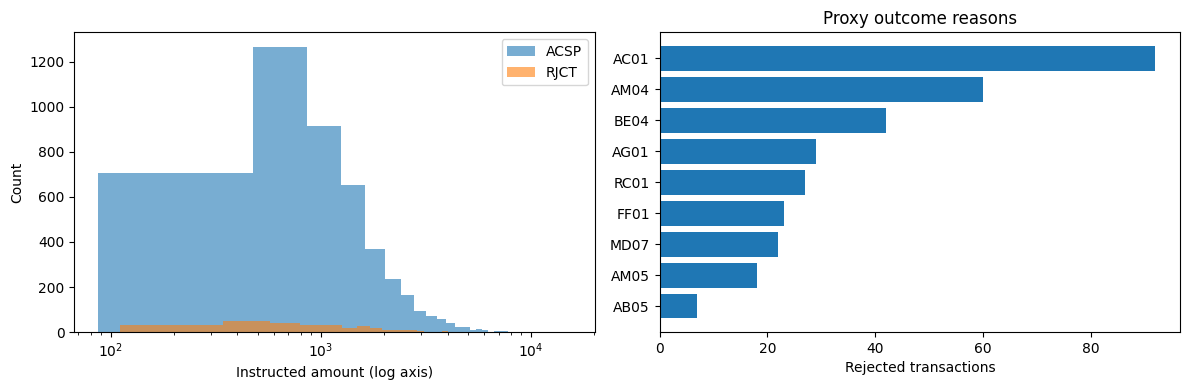

In [ ]:
#@title Table 4 + Figure 1 — Descriptive outcome profile
reason=df.loc[y==1,"RejectionReason"].fillna("<missing>").value_counts().rename_axis("RejectionReason").reset_index(name="n")
show_table(reason,"T04_rejection_reasons","Table 4. Rejection-reason profile (evaluation only; not model inputs).")
fig,ax=plt.subplots(1,2,figsize=(12,4))
ax[0].hist(df.loc[y==0,"InstdAmt"],bins=40,alpha=.6,label="ACSP"); ax[0].hist(df.loc[y==1,"InstdAmt"],bins=40,alpha=.6,label="RJCT"); ax[0].set_xscale("log"); ax[0].set_xlabel("Instructed amount (log axis)"); ax[0].set_ylabel("Count"); ax[0].legend()
rr=reason.sort_values("n"); ax[1].barh(rr.RejectionReason,rr.n); ax[1].set_xlabel("Rejected transactions"); ax[1].set_title("Proxy outcome reasons")
fig.tight_layout(); show_figure(fig,"F01_descriptive","Figure 1. Amount distribution and proxy rejection-reason composition.")


## 3. Ex-ante ISO-domain feature engineering and chronological lockbox

Feature engineering is restricted to row-local or backward-looking information: monetary structure, calendar cycles, settlement lag, agent/country tokens and causal velocity counters. No precomputed “valid/invalid” relationship flag is supplied; the Transformer must learn cross-field dependence itself.


In [ ]:
#@title Table 5 — Modelling features and ISO semantic groups
F=D.build_ex_ante_frame(df); splits=D.chronological_split(df)
feat_rows=[]
for g,cols in D.SEMANTIC_GROUPS.items():
    for c in cols: feat_rows.append({"Semantic group":g,"Feature":c,"Type":"numeric" if c in D.NUMERIC_FEATURES else "categorical"})
show_table(pd.DataFrame(feat_rows),"T05_feature_map","Table 5. Leakage-safe ex-ante modelling features and equal-weight ISO semantic groups.")


**Table 5. Leakage-safe ex-ante modelling features and equal-weight ISO semantic groups.**

,Semantic group,Feature,Type
0,value,log_amount,numeric
1,value,amt_cents,numeric
2,value,Currency,categorical
3,routing,DbtrAgtBIC,categorical
4,routing,CdtrAgtBIC,categorical
5,routing,DbtrCountry,categorical
6,routing,CdtrCountry,categorical
7,routing,dbtr_bic_ctry,categorical
8,routing,cdtr_bic_ctry,categorical
9,purpose,PurposeCode,categorical


**Table 6. Chronological fit/tune/reference/calibration/final-test lockbox.**

,Partition,n,Start,End,ACSP,RJCT,RJCT_rate
0,FIT,2500,2025-01-01 09:01:24,2025-01-16 09:38:21,2332,168,0.0672
1,TUNE,500,2025-01-16 09:40:58,2025-01-19 10:50:13,478,22,0.0440
2,REF,500,2025-01-19 10:52:44,2025-01-22 09:44:25,470,30,0.0600
3,CAL,500,2025-01-22 09:49:12,2025-01-25 09:29:22,469,31,0.0620
4,TEST,1000,2025-01-25 09:33:22,2025-01-30 16:58:44,931,69,0.0690


**Figure 2. Final chronological research design; the last 20% is touched only once for headline evaluation.**

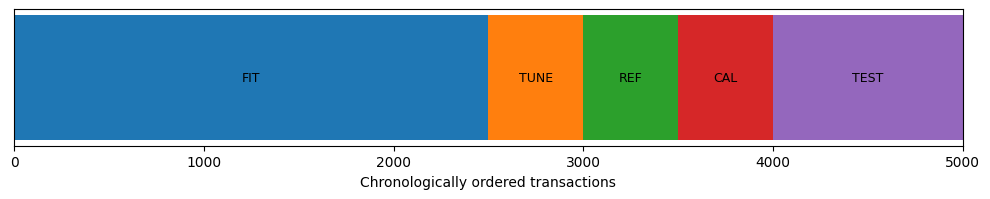

In [ ]:
#@title Table 6 + Figure 2 — Chronological split
rows=[]
for name,idx in splits.items():
    rows.append({"Partition":name,"n":len(idx),"Start":df.TxDateTime.iloc[idx].min(),"End":df.TxDateTime.iloc[idx].max(),"ACSP":int((y[idx]==0).sum()),"RJCT":int((y[idx]==1).sum()),"RJCT_rate":y[idx].mean()})
split_tbl=pd.DataFrame(rows); show_table(split_tbl,"T06_chronological_split","Table 6. Chronological fit/tune/reference/calibration/final-test lockbox.")
fig,ax=plt.subplots(figsize=(10,2.1)); x=0
for _,r in split_tbl.iterrows():
    ax.barh([0],[r.n],left=x,label=r.Partition); ax.text(x+r.n/2,0,str(r.Partition),ha="center",va="center",fontsize=9); x+=r.n
ax.set_yticks([]); ax.set_xlabel("Chronologically ordered transactions"); ax.set_xlim(0,len(df)); fig.tight_layout(); show_figure(fig,"F02_split","Figure 2. Final chronological research design; the last 20% is touched only once for headline evaluation.")


## 4. Why CTGAN is disabled in the headline model

CTGAN is a data generator, not the anomaly detector. In the earlier version it generated 28,100 synthetic normal rows from 2,810 real development-normal rows. Hyperparameters were selected on real data but the final MTT was fitted on an eleven-times-larger, mostly synthetic distribution. This mismatch can weaken final generalisation and makes the ablation difficult to interpret.

The main analysis therefore uses real development-normal transactions only. CTGAN may be studied later as a separate ablation after adding fidelity, duplicate, privacy, distribution-shift and augmentation-ratio checks.


In [ ]:
#@title CTGAN decision gate
USE_CTGAN=False
gan_decision=pd.DataFrame([{
    "Component":"CTGAN normal augmentation",
    "Headline run":"Disabled",
    "Reason":"10:1 synthetic-to-real augmentation was introduced after HPO and had no fidelity gate",
    "Scientific treatment":"Optional future ablation only",
}])
show_table(gan_decision,"T06A_gan_decision","Table 6A. CTGAN is excluded from the main model to keep fitting consistent with hyperparameter selection.")


**Table 6A. CTGAN is excluded from the main model to keep fitting consistent with hyperparameter selection.**

,Component,Headline run,Reason,Scientific treatment
0,CTGAN normal augmentation,Disabled,10:1 synthetic-to-real augmentation was introd...,Optional future ablation only


## 4. Dependency audit and supervised label-detectability diagnostic

The proposal endpoint remains primary regardless of this diagnostic. The supervised probe is **not called a theoretical ceiling**; it only asks whether strong supervised models can discover appreciable recoverable association in the supplied ex-ante predictors. It is never used to select the anomaly detectors.


**Table 7. Strongest categorical dependencies learned only from FIT accepted traffic.**

,Feature A,Feature B,Cramers_V
0,DbtrCountry,dbtr_bic_ctry,1.000000
1,CdtrCountry,cdtr_bic_ctry,1.000000
2,DbtrAgtBIC,DbtrCountry,0.998065
3,DbtrAgtBIC,dbtr_bic_ctry,0.998065
4,CdtrAgtBIC,cdtr_bic_ctry,0.998064
5,CdtrAgtBIC,CdtrCountry,0.998064
6,CdtrAgtBIC,DbtrCountry,0.404464
7,CdtrAgtBIC,dbtr_bic_ctry,0.404464
8,CdtrCountry,dbtr_bic_ctry,0.402174
9,DbtrCountry,CdtrCountry,0.402174


**Figure 3. Dependency structure available for masked reconstruction to learn.**

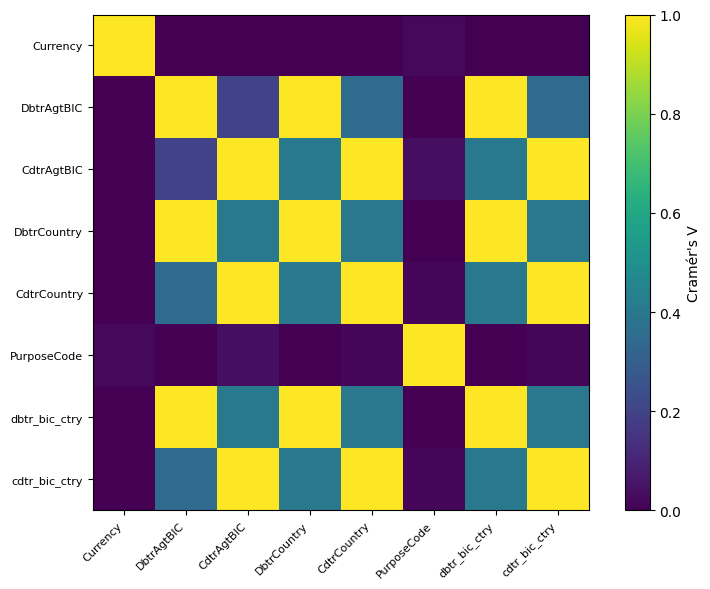

In [ ]:
#@title Table 7 + Figure 3 — Inter-feature dependency map on FIT accepted traffic
fit_idx=splits["FIT"]; fit_norm_idx=fit_idx[y[fit_idx]==0]; dep=D.dependency_audit(F.iloc[fit_norm_idx])
show_table(dep.head(25),"T07_dependency_audit","Table 7. Strongest categorical dependencies learned only from FIT accepted traffic.")
# heat map
cats=D.CATEGORICAL_FEATURES; mat=np.eye(len(cats))
lookup={(r["Feature A"],r["Feature B"]):r.Cramers_V for _,r in dep.iterrows()}
for i,a in enumerate(cats):
    for j,b in enumerate(cats):
        if i<j: mat[i,j]=mat[j,i]=lookup.get((a,b),lookup.get((b,a),np.nan))
fig,ax=plt.subplots(figsize=(8,6)); im=ax.imshow(mat,vmin=0,vmax=1,cmap="viridis"); ax.set_xticks(range(len(cats))); ax.set_xticklabels(cats,rotation=45,ha="right",fontsize=8); ax.set_yticks(range(len(cats))); ax.set_yticklabels(cats,fontsize=8); fig.colorbar(im,ax=ax,label="Cramér's V"); fig.tight_layout(); show_figure(fig,"F03_dependency_heatmap","Figure 3. Dependency structure available for masked reconstruction to learn.")


In [ ]:
#@title Table 8 — Supervised detectability probe (diagnostic only)
probe_F=F.copy(); probe_F=probe_F[D.NUMERIC_FEATURES+D.CATEGORICAL_FEATURES]
# To keep smoke runs fast, use fewer null permutations there.
probe=S.supervised_detectability_probe(probe_F,y,seeds=tuple(SEEDS),n_perm=3 if PRESET=="smoke" else 999)
show_table(pd.DataFrame([probe]),"T08_detectability_probe","Table 8. Supervised label-detectability diagnostic; this does not change the proposal endpoint.")


**Table 8. Supervised label-detectability diagnostic; this does not change the proposal endpoint.**

,Observed_AUROC,Observed_SD,Permutation_mean,Permutation_SD,p_value,n_permutations
0,0.497364,0.025549,0.500603,0.021277,0.572,999


## 5. Self-supervised development corruption set

Hyperparameters must not be tuned on `TxSts`. Instead, the notebook creates a balanced development set from **TUNE accepted records only**, with corruption rules whose support is learned from **FIT accepted records only**. This is a self-supervised validation device: the “labels” are generated by our own masking/corruption process, never by the downstream payment status.

The corruption set deliberately mixes relational and marginal anomalies and contains a currency-shuffle null/control family. It is used for **HPO only**; the final primary performance still uses the untouched `TxSts` lockbox.


In [ ]:
#@title Table 9 — Controlled development corruption families
fit_norm=F.iloc[fit_norm_idx].copy()
tune_idx=splits["TUNE"]; tune_norm_idx=tune_idx[y[tune_idx]==0]; tune_norm=F.iloc[tune_norm_idx].copy()
if PRESET=="smoke":
    fit_norm=fit_norm.iloc[:800].copy(); tune_norm=tune_norm.iloc[:180].copy()
pseudo=D.make_pseudo_anomalies(tune_norm,fit_norm,seed=SEEDS[0],fraction=CFG["pseudo_fraction"],all_families=False)
counts=pseudo.groupby(["__y__","__family__"]).size().rename("n").reset_index()
show_table(counts,"T09_pseudo_tuning","Table 9. Balanced self-supervised development corruption set; no TxSts/RejectionReason is used.")


**Table 9. Balanced self-supervised development corruption set; no TxSts/RejectionReason is used.**

,__y__,__family__,n
0,0,normal,478
1,1,A1_dbtr_BIC_country,80
2,1,A2_cdtr_BIC_country,80
3,1,A3_rare_coherent_route,80
4,1,A4_settlement_lag,80
5,1,A5_amount_tail,79
6,1,A6_currency_null,79


## 6. Hyperparameter tuning — MTT, classical baselines and denoising AE

The MTT is tuned with Optuna. The objective is pseudo-anomaly AUPRC on the self-supervised TUNE corruption set with a very small reconstruction-loss regulariser. The scoring rule (group mean, top-2 group, max group, covariance residual or fixed blends) is selected in the same label-free manner.

Every classical baseline is tuned on the **same** pseudo-anomaly set, preventing an unfair “tuned Transformer vs default baselines” comparison.


trial 01/60: pseudo AUPRC=0.8365  method=blend_50_50  recon=0.3285
trial 02/60: pseudo AUPRC=0.8667  method=blend_50_50  recon=0.2501
trial 03/60: pseudo AUPRC=0.8311  method=blend_50_50  recon=0.2149
trial 04/60: pseudo AUPRC=0.8755  method=blend_50_50  recon=0.3156
trial 05/60: pseudo AUPRC=0.8536  method=blend_50_50  recon=0.1973
trial 06/60: pseudo AUPRC=0.8670  method=blend_50_50  recon=0.2761
trial 07/60: pseudo AUPRC=0.8874  method=blend_50_50  recon=0.2297
trial 08/60: pseudo AUPRC=0.8659  method=blend_50_50  recon=0.2240
trial 09/60: pseudo AUPRC=0.8862  method=blend_50_50  recon=0.2188
trial 10/60: pseudo AUPRC=0.8676  method=blend_50_50  recon=0.2787
trial 11/60: pseudo AUPRC=0.9008  method=blend_50_50  recon=0.2779
trial 12/60: pseudo AUPRC=0.8712  method=blend_50_50  recon=0.2875
trial 13/60: pseudo AUPRC=0.8410  method=blend_50_50  recon=0.2087
trial 14/60: pseudo AUPRC=0.8715  method=blend_50_50  recon=0.2711
trial 15/60: pseudo AUPRC=0.8678  method=blend_50_50  recon=0.

**Table 10. Label-free/self-supervised MTT hyperparameter search ranked by development objective.**

,d_token,n_layers,n_heads,d_ff_mult,dropout,mask_ratio,lr,weight_decay,epochs,batch_size,score_method,pseudo_AUPRC,val_recon_loss,objective,seconds
0,64,4,8,4.0,0.20,0.70,0.000270,0.000392,45,256,blend_50_50,0.921535,0.318750,0.918768,163.562915
1,64,4,8,4.0,0.20,0.70,0.000235,0.000108,45,256,blend_50_50,0.914520,0.327020,0.911691,158.166524
2,64,4,8,4.0,0.10,0.75,0.000348,0.000287,45,256,blend_50_50,0.911359,0.339274,0.908437,156.306779
3,64,4,8,4.0,0.10,0.75,0.000249,0.000096,45,256,blend_50_50,0.910204,0.340068,0.907277,150.180552
4,64,3,8,4.0,0.20,0.75,0.000242,0.000170,45,256,blend_50_50,0.909529,0.336883,0.906626,123.277155
5,64,3,8,4.0,0.15,0.75,0.000286,0.000073,45,256,blend_50_50,0.909214,0.338940,0.906296,117.855896
6,64,4,8,4.0,0.25,0.75,0.000399,0.000331,45,256,blend_50_50,0.906479,0.332467,0.903609,163.269155
7,64,4,8,4.0,0.15,0.75,0.000294,0.000141,45,256,blend_50_50,0.905447,0.334797,0.902559,154.803598
8,64,4,8,4.0,0.20,0.70,0.000263,0.000401,45,256,blend_50_50,0.905208,0.331320,0.902346,162.322846
9,64,3,8,4.0,0.20,0.75,0.000358,0.000071,45,256,blend_50_50,0.903358,0.338832,0.900440,121.300740


BEST_MTT = {'d_token': 64, 'n_layers': 4, 'n_heads': 8, 'd_ff_mult': 4.0, 'dropout': 0.2, 'mask_ratio': 0.7, 'lr': 0.00026952403685947765, 'weight_decay': 0.00039238287930417747, 'epochs': 90, 'batch_size': 256, 'score_method': 'blend_50_50'} 
HPO minutes = 119.99717213726666


**Figure 4. HPO trials: reconstruction quality need not perfectly predict anomaly separation.**

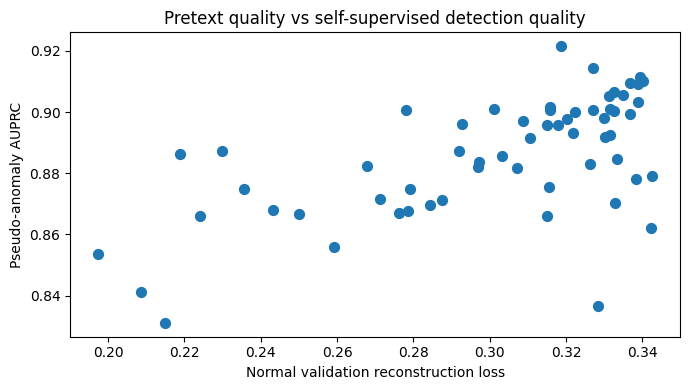

In [ ]:
#@title Table 10 + Figure 4 — MTT Optuna search
seed_all(SEEDS[0]); t0=time.perf_counter()
hpo,BEST_MTT,_=E.mtt_hpo(fit_norm,tune_norm,pseudo,n_trials=CFG["hpo_trials"],hpo_epochs=CFG["hpo_epochs"],seed=SEEDS[0],device=DEVICE)
BEST_MTT["epochs"]=CFG["final_epochs"]
show_table(hpo,"T10_mtt_hpo","Table 10. Label-free/self-supervised MTT hyperparameter search ranked by development objective.")
print("BEST_MTT =",BEST_MTT,"\nHPO minutes =",(time.perf_counter()-t0)/60)
fig,ax=plt.subplots(figsize=(7,4)); ax.scatter(hpo["val_recon_loss"],hpo["pseudo_AUPRC"],s=50); ax.set_xlabel("Normal validation reconstruction loss"); ax.set_ylabel("Pseudo-anomaly AUPRC"); ax.set_title("Pretext quality vs self-supervised detection quality"); fig.tight_layout(); show_figure(fig,"F04_hpo","Figure 4. HPO trials: reconstruction quality need not perfectly predict anomaly separation.")


In [ ]:
#@title Table 11 — Fair baseline tuning on identical pseudo anomalies
baseline_tuning,BEST_BASE=E.tune_baselines(fit_norm,pseudo,seed=SEEDS[0])
show_table(baseline_tuning,"T11_baseline_hpo","Table 11. Classical-baseline tuning on the same self-supervised development corruption set.")
print("Selected baseline parameters:",json.dumps(BEST_BASE,indent=2,default=str))


**Table 11. Classical-baseline tuning on the same self-supervised development corruption set.**

,Detector,Params,Pseudo_AUPRC,Seconds
19,GMM,{'n_components': 5},0.866123,0.092373
18,GMM,{'n_components': 3},0.843082,0.046322
17,GMM,{'n_components': 2},0.804257,0.064375
16,GMM,{'n_components': 1},0.693448,0.066947
2,IsolationForest,"{'n_estimators': 500, 'max_features': 0.7}",0.548743,1.422707
3,IsolationForest,"{'n_estimators': 500, 'max_features': 1.0}",0.539546,1.261752
1,IsolationForest,"{'n_estimators': 300, 'max_features': 1.0}",0.537689,0.775047
4,LOF,{'n_neighbors': 10},0.897272,0.119918
5,LOF,{'n_neighbors': 20},0.893258,0.097147
6,LOF,{'n_neighbors': 35},0.891689,0.112415


Selected baseline parameters: {
  "Z-score": {},
  "IsolationForest": {
    "n_estimators": 500,
    "max_features": 0.7
  },
  "LOF": {
    "n_neighbors": 10
  },
  "OCSVM": {
    "nu": 0.02,
    "gamma": "scale"
  },
  "PCA-recon": {
    "n_components": 10
  },
  "GMM": {
    "n_components": 5
  },
  "Marginal-NLL": {}
}


In [ ]:
#@title Table 12 — Denoising autoencoder tuning
DAE_TUNE,BEST_DAE=E.tune_dae(fit_norm,pseudo,seed=SEEDS[0],device=DEVICE,epochs=min(CFG["dae_epochs"],CFG["hpo_epochs"]+10),n_configs=1 if PRESET=="smoke" else 3)
BEST_DAE["epochs"]=CFG["dae_epochs"]
show_table(DAE_TUNE,"T12_dae_hpo","Table 12. Denoising-autoencoder deep baseline tuning using the same pseudo-anomaly protocol.")
print("BEST_DAE =",BEST_DAE)

**Table 12. Denoising-autoencoder deep baseline tuning using the same pseudo-anomaly protocol.**

,d_token,dropout,mask_ratio,lr,weight_decay,epochs,score_method,pseudo_AUPRC,seconds
0,64,0.2,0.2,0.0005,0.00010,55,blend_50_50,0.895201,18.413510
1,48,0.1,0.2,0.0008,0.00001,55,blend_50_50,0.891233,13.056946
2,32,0.1,0.1,0.0010,0.00001,55,blend_50_50,0.886663,8.795551


BEST_DAE = {'d_token': 64, 'dropout': 0.2, 'mask_ratio': 0.2, 'lr': 0.0005, 'weight_decay': 0.0001, 'epochs': 60, 'score_method': 'blend_50_50'}


## 7. Strong self-supervised controlled-anomaly reference

This model is added to the full comparison because a high metric should first be shown on a target that the available fields can represent. Extra Trees is trained on controlled corruptions created from FIT accepted traffic, tuned on a separate TUNE corruption set and scored once on an independently generated TEST controlled lockbox.

It is a strong non-neural reference, not a replacement label for the MTT. The MTT, denoising autoencoder and classical models are compared with it later on the same controlled TEST records.


In [ ]:
#@title Train, tune and independently test the self-supervised reference
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder,RobustScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import (average_precision_score,roc_auc_score,precision_recall_curve,
                             precision_score,recall_score,f1_score,balanced_accuracy_score)

# Separate support rows from pseudo-training rows inside FIT.
reference_size=1200 if len(fit_norm)>1600 else max(200,len(fit_norm)//2)
SS_REFERENCE=fit_norm.iloc[:reference_size].copy()
SS_TRAIN_NORMAL=fit_norm.iloc[reference_size:].copy()
SS_CONTROLLED_TRAIN=D.make_pseudo_anomalies(SS_TRAIN_NORMAL,SS_REFERENCE,seed=7,fraction=1.0,all_families=False)
SS_CONTROLLED_TUNE=D.make_pseudo_anomalies(tune_norm,SS_REFERENCE,seed=SEEDS[0],fraction=CFG["pseudo_fraction"],all_families=False)

def split_controlled(frame):
    x=frame.drop(columns=["__y__","__family__"])
    return x,frame["__y__"].to_numpy(int),frame["__family__"].to_numpy(str)

X_ss_train,y_ss_train,_=split_controlled(SS_CONTROLLED_TRAIN)
X_ss_tune,y_ss_tune,_=split_controlled(SS_CONTROLLED_TUNE)

def build_ss_model(min_samples_leaf,max_features):
    pre=ColumnTransformer([
        ("num",RobustScaler(),D.NUMERIC_FEATURES),
        ("cat",OneHotEncoder(handle_unknown="ignore",sparse_output=False),D.CATEGORICAL_FEATURES),
    ])
    trees=ExtraTreesClassifier(n_estimators=500 if PRESET!="smoke" else 150,
        min_samples_leaf=int(min_samples_leaf),max_features=float(max_features),
        class_weight="balanced",random_state=SEEDS[0],n_jobs=-1)
    return make_pipeline(pre,trees)

ss_rows=[]
for leaf in ([1,2,4,8] if PRESET!="smoke" else [1,2]):
    for fraction in ([.5,.8,1.0] if PRESET!="smoke" else [.5,1.0]):
        candidate=build_ss_model(leaf,fraction).fit(X_ss_train,y_ss_train)
        score=candidate.predict_proba(X_ss_tune)[:,1]
        ss_rows.append({"min_samples_leaf":leaf,"max_features":fraction,
                        "TUNE_AUPRC":average_precision_score(y_ss_tune,score),
                        "TUNE_AUROC":roc_auc_score(y_ss_tune,score)})
SS_TUNING=pd.DataFrame(ss_rows).sort_values(["TUNE_AUPRC","TUNE_AUROC"],ascending=False).reset_index(drop=True)
SS_BEST=SS_TUNING.iloc[0].to_dict()
SS_MODEL=build_ss_model(SS_BEST["min_samples_leaf"],SS_BEST["max_features"]).fit(X_ss_train,y_ss_train)

ss_tune_score=SS_MODEL.predict_proba(X_ss_tune)[:,1]
p_tune,r_tune,t_tune=precision_recall_curve(y_ss_tune,ss_tune_score)
f_tune=2*p_tune[:-1]*r_tune[:-1]/np.maximum(p_tune[:-1]+r_tune[:-1],1e-12)
SS_CONTROLLED_THRESHOLD=float(t_tune[np.argmax(f_tune)])

# Independent controlled TEST lockbox: one corruption per accepted test transaction.
test_normal_feature=F.iloc[splits["TEST"][y[splits["TEST"]]==0]].copy()
SS_CONTROLLED_TEST=D.make_pseudo_anomalies(test_normal_feature,SS_REFERENCE,seed=SEEDS[1],fraction=1.0,all_families=False)
X_ss_test,y_ss_test,family_ss_test=split_controlled(SS_CONTROLLED_TEST)
ss_test_score=SS_MODEL.predict_proba(X_ss_test)[:,1]

def ss_metrics(mask):
    yt=y_ss_test[mask]; st=ss_test_score[mask]; pred=(st>=SS_CONTROLLED_THRESHOLD).astype(int)
    return {"AUROC":roc_auc_score(yt,st),"AUPRC":average_precision_score(yt,st),
            "Precision":precision_score(yt,pred,zero_division=0),"Recall":recall_score(yt,pred,zero_division=0),
            "F1":f1_score(yt,pred,zero_division=0),"BalancedAccuracy":balanced_accuracy_score(yt,pred)}

mask_all=np.ones(len(y_ss_test),dtype=bool)
mask_detectable=family_ss_test!="A6_currency_null"
SS_CONTROLLED_RESULTS=pd.DataFrame([
    {"Endpoint":"All families including null control",**ss_metrics(mask_all)},
    {"Endpoint":"Five detectable ISO-violation families",**ss_metrics(mask_detectable)},
])

family_rows=[]
for family in sorted(set(family_ss_test)-{"normal"}):
    mask=(family_ss_test=="normal")|(family_ss_test==family)
    family_rows.append({"Family":family,"Anomaly_n":int(y_ss_test[mask].sum()),
                        "AUROC":roc_auc_score(y_ss_test[mask],ss_test_score[mask]),
                        "AUPRC":average_precision_score(y_ss_test[mask],ss_test_score[mask])})
SS_FAMILY_RESULTS=pd.DataFrame(family_rows).sort_values("AUROC",ascending=False)

show_table(SS_TUNING.head(12),"T12A_ss_tuning","Table 12A. Self-supervised reference tuning on controlled TUNE only.")
show_table(SS_CONTROLLED_RESULTS,"T12B_ss_controlled","Table 12B. Independent controlled TEST metrics for the strong self-supervised reference.")
show_table(SS_FAMILY_RESULTS,"T12C_ss_families","Table 12C. Per-family controlled TEST metrics; the currency null control should remain near chance.")
print("Frozen controlled threshold:",SS_CONTROLLED_THRESHOLD)


**Table 12A. Self-supervised reference tuning on controlled TUNE only.**

,min_samples_leaf,max_features,TUNE_AUPRC,TUNE_AUROC
0,1,0.5,0.940112,0.916786
1,2,0.5,0.939483,0.914872
2,4,0.5,0.937731,0.912272
3,1,0.8,0.936209,0.911580
4,2,0.8,0.935446,0.910151
5,4,0.8,0.934072,0.907541
6,8,0.8,0.933824,0.907274
7,8,0.5,0.932990,0.906814
8,8,1.0,0.932810,0.905295
9,1,1.0,0.931314,0.907201


**Table 12B. Independent controlled TEST metrics for the strong self-supervised reference.**

,Endpoint,AUROC,AUPRC,Precision,Recall,F1,BalancedAccuracy
0,All families including null control,0.909065,0.937541,0.911137,0.825994,0.866479,0.872718
1,Five detectable ISO-violation families,0.991370,0.989721,0.909964,0.976804,0.942200,0.948123


**Table 12C. Per-family controlled TEST metrics; the currency null control should remain near chance.**

,Family,Anomaly_n,AUROC,AUPRC
3,A4_settlement_lag,155,0.999480,0.997150
4,A5_amount_tail,155,0.996029,0.973657
0,A1_dbtr_BIC_country,156,0.990226,0.967856
1,A2_cdtr_BIC_country,155,0.987211,0.939717
2,A3_rare_coherent_route,155,0.983909,0.904485
5,A6_currency_null,155,0.497013,0.140753


Frozen controlled threshold: 0.43


## 8. Final model fitting: two seeds, leave-one-feature-out reconstruction and lockbox scoring

After tuning is frozen, FIT and TUNE accepted transactions are combined for final normal-only training. REF remains separate to calibrate heterogeneous reconstruction losses, CAL remains separate for the split-conformal threshold, and TEST remains untouched until scoring.

The primary MTT score is a **two-seed ensemble**: each independently initialised MTT produces a deterministic leave-one-feature-out reconstruction score, and the two transaction scores are averaged. This reduces neural seed variance without creating pseudo-replication: each final transaction still contributes exactly one ensemble score to statistical inference.


In [ ]:
#@title Prepare final real-only train/reference/calibration/test arrays
dev_idx=np.r_[splits["FIT"],splits["TUNE"]]; dev_norm_idx=dev_idx[y[dev_idx]==0]
ref_idx=splits["REF"]; ref_norm_idx=ref_idx[y[ref_idx]==0]
cal_idx=splits["CAL"]; cal_norm_idx=cal_idx[y[cal_idx]==0]
test_idx=splits["TEST"]
if PRESET=="smoke":
    dev_norm_idx=dev_norm_idx[:900]; ref_norm_idx=ref_norm_idx[:150]; cal_norm_idx=cal_norm_idx[:150]; test_idx=test_idx[:300]
y_test=y[test_idx]

# Final fitting now matches HPO: only real accepted development transactions are used.
F_dev_real=F.iloc[dev_norm_idx].copy()
ENC=D.FitOnTrain(min_freq=2).fit(F_dev_real)
Xn_dev,Xc_dev=ENC.transform(F_dev_real)
Xn_ref,Xc_ref=ENC.transform(F.iloc[ref_norm_idx])
Xn_cal,Xc_cal=ENC.transform(F.iloc[cal_norm_idx])
Xn_test,Xc_test=ENC.transform(F.iloc[test_idx])

CAT_SIZES=[ENC.cat_sizes[c] for c in D.CATEGORICAL_FEATURES]
GROUPS=ENC.group_indices()
assert not USE_CTGAN
print("real train normals",len(Xn_dev),"ref normals",len(Xn_ref),"cal normals",len(Xn_cal),"test",len(Xn_test),"test RJCT",int(y_test.sum()))


real train normals 2810 ref normals 470 cal normals 469 test 1000 test RJCT 69


In [ ]:
#@title Train and score the final two-seed MTT ensemble
MTT_RUNS=[]; seed_rows=[]
for seed in SEEDS:
    seed_all(seed); p=dict(BEST_MTT); p["epochs"]=CFG["final_epochs"]
    model,info=E.fit_mtt(Xn_dev,Xc_dev,CAT_SIZES,p,seed,DEVICE)
    t=time.perf_counter(); L_ref=M.loo_loss_matrix(model,Xn_ref,Xc_ref,device=DEVICE); L_cal=M.loo_loss_matrix(model,Xn_cal,Xc_cal,device=DEVICE); L_test=M.loo_loss_matrix(model,Xn_test,Xc_test,device=DEVICE); score_secs=time.perf_counter()-t
    scorer=M.ReconScoreModel(GROUPS).fit(L_ref); method=str(BEST_MTT["score_method"])
    s_ref=scorer.score(L_ref,method); s_cal=scorer.score(L_cal,method); s_test=scorer.score(L_test,method)
    th=S.conformal_threshold(s_cal,ALPHA_FPR)
    seed_rows.append({"Seed":seed,**S.ranking_metrics(y_test,s_test),**S.threshold_metrics(y_test,s_test,th),"Fit_s":info["fit_seconds"],"LOO_score_s":score_secs,"Parameters":M.count_parameters(model)})
    MTT_RUNS.append(dict(seed=seed,model=model,scorer=scorer,L_ref=L_ref,L_cal=L_cal,L_test=L_test,s_ref=s_ref,s_cal=s_cal,s_test=s_test,threshold=th,info=info))
    torch.save(model.state_dict(),MODEL_DIR/f"mtt_seed_{seed}.pt")
    print(seed,"done: AUROC",seed_rows[-1]["AUROC"],"AUPRC",seed_rows[-1]["AUPRC"])
MTT_SEED_TABLE=pd.DataFrame(seed_rows); show_table(MTT_SEED_TABLE,"T13_mtt_seed_results","Table 13. Two independent MTT seeds on the same untouched final lockbox.")


42 done: AUROC 0.4505051448497019 AUPRC 0.06076220345984684
2026 done: AUROC 0.49381217017699536 AUPRC 0.06875017994654925


**Table 13. Two independent MTT seeds on the same untouched final lockbox.**

,Seed,AUROC,AUPRC,AUPRC_lift,Precision@1%,Recall@1%,F1@1%,Lift@1%,Precision@5%,Recall@5%,...,Specificity,FPR,MCC,TP,FP,TN,FN,Fit_s,LOO_score_s,Parameters
0,42,0.450505,0.060762,0.880612,0.1,0.014493,0.025316,1.449275,0.02,0.014493,...,0.957035,0.042965,-0.036393,1,40,891,68,390.841251,13.128421,212098
1,2026,0.493812,0.068750,0.996379,0.1,0.014493,0.025316,1.449275,0.06,0.043478,...,0.960258,0.039742,-0.033471,1,37,894,68,391.204345,13.331549,212098


### 8a. Learnability-weighted scoring (new in v5)

About ten of the eighteen fields (currency, purpose, hour/weekday, cents, velocity) are statistically independent noise in this corpus. Their masked-reconstruction losses cannot separate anomalies from normals, but they still enter the group-mean / blend scores and dilute the ones that can. Here the per-field weights are learned from a **controlled anomaly set built on REF normals** (never trained on; `TxSts` is not used; the A6 null-control rows are excluded) and then **frozen before the lockbox is scored**.

In [ ]:
#@title Table 13B — Learn per-field weights on a controlled REF set (no TxSts; frozen before the lockbox)
_wf=F.iloc[ref_norm_idx].copy().reset_index(drop=True)
W_SET=D.make_pseudo_anomalies(_wf,SS_REFERENCE,seed=SEEDS[0]+101,fraction=1.0,all_families=False)
_wy=W_SET.pop("__y__").to_numpy(int); _wfam=W_SET.pop("__family__").to_numpy(str)
_wxn,_wxc=ENC.transform(W_SET); _wkeep=_wfam!="A6_currency_null"   # null control has no detectable signal by construction
FIELD_NAMES=D.NUMERIC_FEATURES+D.CATEGORICAL_FEATURES
FIELD_W=pd.DataFrame({"Field":FIELD_NAMES})
for r in MTT_RUNS:
    Lw=M.loo_loss_matrix(r["model"],_wxn,_wxc,DEVICE)
    r["scorer"].fit_field_weights(Lw[_wkeep],_wy[_wkeep],min_auroc=0.53)
    FIELD_W[f"AUROC_seed{r['seed']}"]=r["scorer"].field_auroc
    FIELD_W[f"Kept_seed{r['seed']}"]=r["scorer"].field_w.astype(int)
    for meth in M.LEARNED_SCORE_METHODS:
        r["s_cal_"+meth]=r["scorer"].score(r["L_cal"],meth); r["s_test_"+meth]=r["scorer"].score(r["L_test"],meth)
show_table(FIELD_W.sort_values(FIELD_W.columns[1],ascending=False).reset_index(drop=True),"T13B_field_weights","Table 13B. Per-field standalone AUROC on the controlled REF set (A6 excluded) and the fields kept by learnability weighting.")
# Sanity check on the TxSts proxy: the label is independent of the inputs, so these MUST stay near chance.
for meth in M.LEARNED_SCORE_METHODS:
    sc=np.mean([r["s_test_"+meth] for r in MTT_RUNS],axis=0); mm=S.ranking_metrics(y_test,sc)
    print(f"TxSts proxy, MTT {meth}: AUROC={mm['AUROC']:.3f} AUPRC={mm['AUPRC']:.3f} (prevalence {y_test.mean():.3f}) -> expected ~chance")

**Table 13B. Per-field standalone AUROC on the controlled REF set (A6 excluded) and the fields kept by learnability weighting.**

,Field,AUROC_seed42,Kept_seed42,AUROC_seed2026,Kept_seed2026
0,CdtrAgtBIC,0.659574,1,0.681527,1
1,settle_lag_days,0.624360,1,0.668541,1
2,vel_sameamt_300s,0.608793,1,0.530479,1
3,log_amount,0.603162,1,0.606084,1
4,cdtr_bic_ctry,0.591731,1,0.586705,1
5,CdtrCountry,0.588265,1,0.584072,1
6,dbtr_bic_ctry,0.582211,1,0.515900,0
7,vel_agentpair_60s,0.580544,1,0.481231,0
8,DbtrAgtBIC,0.559276,1,0.583435,1
9,DbtrCountry,0.536887,1,0.527885,0


TxSts proxy, MTT learn_max: AUROC=0.487 AUPRC=0.065 (prevalence 0.069) -> expected ~chance
TxSts proxy, MTT learn_sum: AUROC=0.504 AUPRC=0.070 (prevalence 0.069) -> expected ~chance


In [ ]:
#@title Train and score the final two-seed denoising autoencoder
DAE_RUNS=[]
for si,seed in enumerate(SEEDS):
    p=dict(BEST_DAE); p["epochs"]=CFG["dae_epochs"]
    # Standalone DAE uses a joint MLP and denoising objective.
    hidden=max(64,(Xn_dev.shape[1]+len(CAT_SIZES))*int(p.get("d_token",48))//4)
    model=M.MixedReconstructor(Xn_dev.shape[1],CAT_SIZES,d_token=int(p.get("d_token",48)),dropout=float(p.get("dropout",.1)),encoder="joint_mlp",mlp_hidden=hidden)
    tfit=time.perf_counter(); model,info=M.train_reconstructor(model,Xn_dev,Xc_dev,objective="denoising",mask_ratio=float(p.get("mask_ratio",.2)),epochs=int(p["epochs"]),batch_size=256,lr=float(p.get("lr",8e-4)),weight_decay=float(p.get("weight_decay",1e-5)),device=DEVICE,seed=seed); fit_s=time.perf_counter()-tfit
    ts=time.perf_counter(); Lr=M.autoencoder_loss_matrix(model,Xn_ref,Xc_ref,device=DEVICE); Lc=M.autoencoder_loss_matrix(model,Xn_cal,Xc_cal,device=DEVICE); Lt=M.autoencoder_loss_matrix(model,Xn_test,Xc_test,device=DEVICE); score_s=time.perf_counter()-ts
    sc=M.ReconScoreModel(GROUPS).fit(Lr); method=str(BEST_DAE.get("score_method","group_mean"))
    DAE_RUNS.append(dict(seed=seed,model=model,scorer=sc,s_cal=sc.score(Lc,method),s_test=sc.score(Lt,method),fit_s=fit_s,score_s=score_s,params=M.count_parameters(model)))
    torch.save(model.state_dict(),MODEL_DIR/f"dae_seed_{seed}.pt")
print("DAE runs complete")

DAE runs complete


In [ ]:
#@title Fit and score the seven tuned classical baselines (same preprocessing and two stochastic seeds)
CLASSICAL={}; latency_rows=[]
for name in M.BASELINES:
    stochastic=name in ["IsolationForest","GMM"]
    use_seeds=SEEDS if stochastic else [SEEDS[0]]
    cal_scores=[]; test_scores=[]; fit_total=score_total=0.; objects=[]
    for seed in use_seeds:
        t=time.perf_counter(); det=M.BaselineDetector(name,BEST_BASE[name],seed).fit(Xn_dev,Xc_dev,CAT_SIZES); fit_total+=time.perf_counter()-t
        t=time.perf_counter(); cal_scores.append(det.score(Xn_cal,Xc_cal)); test_scores.append(det.score(Xn_test,Xc_test)); score_total+=time.perf_counter()-t; objects.append(det)
    CLASSICAL[name]=dict(detectors=objects,s_cal=np.mean(cal_scores,axis=0),s_test=np.mean(test_scores,axis=0),fit_s=fit_total,score_s=score_total)
    print(name,"done")


Z-score done
IsolationForest done
LOF done
OCSVM done
PCA-recon done
GMM done
Marginal-NLL done


## 8b. Controlled ISO-dependency benchmark — the endpoint that can actually answer the research question

**Moved up from section 15 in v5.** In the v4 run the notebook stopped inside the ablation ladder, so this benchmark never executed. The `TxSts` proxy cannot answer *"can the model detect anomalies?"* because RJCT is statistically independent of every ex-ante field in this corpus (supervised probe AUROC ≈ 0.50, permutation p = 0.75). The controlled lockbox injects known ISO violations into held-out accepted traffic, so it can.

Variants compared on the same records: standard MTT scoring; **MTT + learned-field weights** (max and sum); **MTT with twin-joint masking** (country and BIC-country masked together). The A6 currency-shuffle family is a pre-specified negative control and must stay near AUROC 0.5.

**Table 25A. Balanced independent controlled TEST comparison; every model scores the same records. Includes the A6 null family, so a perfect detector caps below 1.**

,Model,AUROC,AUPRC,AUPRC_lift,Precision@1%,Recall@1%,F1@1%,Lift@1%,Precision@5%,Recall@5%,F1@5%,Lift@5%
0,Self-supervised Extra Trees,0.909065,0.937541,1.875081,1.000000,0.020408,0.040000,2.000000,1.000000,0.099893,0.181641,2.000000
1,MTT + learned-field max,0.860935,0.900252,1.800503,1.000000,0.020408,0.040000,2.000000,1.000000,0.099893,0.181641,2.000000
2,Denoising AE (2-seed),0.848552,0.896128,1.792256,1.000000,0.020408,0.040000,2.000000,1.000000,0.099893,0.181641,2.000000
3,LOF,0.848962,0.892528,1.785057,1.000000,0.020408,0.040000,2.000000,1.000000,0.099893,0.181641,2.000000
4,GMM,0.826994,0.862797,1.725594,1.000000,0.020408,0.040000,2.000000,1.000000,0.099893,0.181641,2.000000
5,MTT (2-seed ensemble),0.816063,0.861161,1.722322,1.000000,0.020408,0.040000,2.000000,1.000000,0.099893,0.181641,2.000000
6,MTT twin-joint masking,0.807463,0.856676,1.713353,1.000000,0.020408,0.040000,2.000000,1.000000,0.099893,0.181641,2.000000
7,MTT + learned-field sum,0.811807,0.848714,1.697428,1.000000,0.020408,0.040000,2.000000,1.000000,0.099893,0.181641,2.000000
8,PCA-recon,0.779263,0.811919,1.623838,1.000000,0.020408,0.040000,2.000000,1.000000,0.099893,0.181641,2.000000
9,OCSVM,0.703573,0.773182,1.546364,1.000000,0.020408,0.040000,2.000000,1.000000,0.099893,0.181641,2.000000


**Table 25B. Controlled TEST results by anomaly family, including the pre-specified null control (A6).**

,Family,Model,AUROC,AUPRC
0,A1_dbtr_BIC_country,MTT (2-seed ensemble),0.999986,0.999918
4,A1_dbtr_BIC_country,Denoising AE (2-seed),0.999910,0.999467
3,A1_dbtr_BIC_country,MTT twin-joint masking,0.999731,0.998256
12,A1_dbtr_BIC_country,Self-supervised Extra Trees,0.990226,0.967856
1,A1_dbtr_BIC_country,MTT + learned-field max,0.981781,0.921258
2,A1_dbtr_BIC_country,MTT + learned-field sum,0.981079,0.911630
10,A1_dbtr_BIC_country,GMM,0.938755,0.882516
7,A1_dbtr_BIC_country,LOF,0.978001,0.868052
9,A1_dbtr_BIC_country,PCA-recon,0.896031,0.532055
8,A1_dbtr_BIC_country,OCSVM,0.660552,0.243333


**Table 26. Controlled-family AUROC matrix for mechanism comparison.**

Model,Denoising AE (2-seed),GMM,IsolationForest,LOF,MTT (2-seed ensemble),MTT + learned-field max,MTT + learned-field sum,MTT twin-joint masking,Marginal-NLL,OCSVM,PCA-recon,Self-supervised Extra Trees,Z-score
Family,,,,,,,,,,,,,
A1_dbtr_BIC_country,0.999910,0.938755,0.688865,0.978001,0.999986,0.981781,0.981079,0.999731,0.678723,0.660552,0.896031,0.990226,0.483100
A2_cdtr_BIC_country,0.999993,0.999709,0.491757,0.981692,1.000000,0.998926,0.997540,1.000000,0.529046,0.593472,0.892159,0.987211,0.509442
A3_rare_coherent_route,0.604705,0.969856,0.448612,0.619223,0.612772,0.679349,0.580645,0.578358,0.444545,0.457080,0.888708,0.983909,0.471595
A4_settlement_lag,0.999737,0.907093,0.620914,0.999986,0.996979,0.998926,0.905984,0.996992,0.994664,1.000000,1.000000,0.999480,0.994647
A5_amount_tail,0.983847,0.645383,0.631530,0.993001,0.787831,0.995967,0.906621,0.783916,0.937008,0.995662,0.481591,0.996029,0.993174
A6_currency_null,0.502141,0.500450,0.515530,0.521039,0.497623,0.509878,0.497879,0.484540,0.516722,0.514948,0.516333,0.497013,0.486061


**Table 26B. Paired bootstrap ΔAUPRC of each MTT variant against every non-MTT comparator on the controlled lockbox (Holm adjusted). Positive = MTT better.**

,MTT_variant,Comparator,delta_AUPRC,CI_low,CI_high,bootstrap_p,bootstrap_p_Holm
2,MTT (2-seed ensemble),IsolationForest,0.318359,0.294756,0.339022,0.000,0.000
1,MTT (2-seed ensemble),Z-score,0.146487,0.121953,0.170472,0.000,0.000
7,MTT (2-seed ensemble),Marginal-NLL,0.142654,0.119469,0.164804,0.000,0.000
4,MTT (2-seed ensemble),OCSVM,0.087979,0.069918,0.105980,0.000,0.000
5,MTT (2-seed ensemble),PCA-recon,0.049242,0.032878,0.065094,0.000,0.000
6,MTT (2-seed ensemble),GMM,-0.001636,-0.015987,0.012739,0.862,0.928
3,MTT (2-seed ensemble),LOF,-0.031367,-0.043110,-0.020190,0.000,0.000
0,MTT (2-seed ensemble),Denoising AE (2-seed),-0.034967,-0.043531,-0.027073,0.000,0.000
8,MTT (2-seed ensemble),Self-supervised Extra Trees,-0.076380,-0.088645,-0.062968,0.000,0.000
11,MTT + learned-field max,IsolationForest,0.357450,0.333620,0.379210,0.000,0.000


**Figure 10. Controlled TEST AUROC by family: MTT variants versus LOF and the supervised-on-corruptions Extra Trees reference (an upper-bound style comparator).**

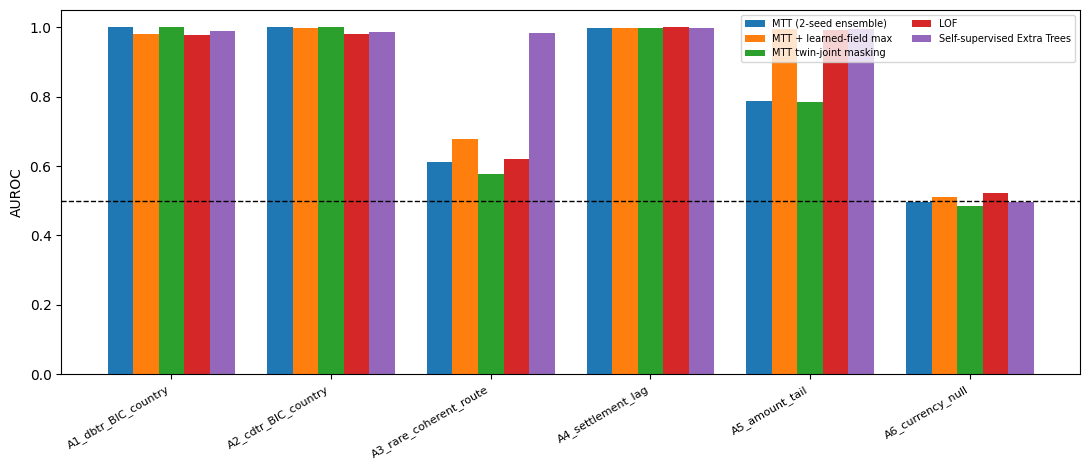

In [ ]:
#@title Tables 25A–26 + Figure 10 — Balanced independent controlled benchmark (PRIMARY structural endpoint)
if RUN_CONTROLLED_BENCHMARK:
    ctrl=SS_CONTROLLED_TEST.copy()
    cy=ctrl.pop("__y__").to_numpy(int)
    cfam=ctrl.pop("__family__").to_numpy(str)
    cxn,cxc=ENC.transform(ctrl)
    ctrl_scores={}
    TWIN_BLOCKS=M.twin_blocks(D.NUMERIC_FEATURES+D.CATEGORICAL_FEATURES)
    mtt_std=[];mtt_lmax=[];mtt_lsum=[];mtt_twin=[]
    for r in MTT_RUNS:
        Lc=M.loo_loss_matrix(r["model"],cxn,cxc,DEVICE)
        mtt_std.append(r["scorer"].score(Lc,str(BEST_MTT["score_method"])))
        mtt_lmax.append(r["scorer"].score(Lc,"learn_max")); mtt_lsum.append(r["scorer"].score(Lc,"learn_sum"))
        Lr_t=M.loo_loss_matrix(r["model"],Xn_ref,Xc_ref,DEVICE,blocks=TWIN_BLOCKS); Lc_t=M.loo_loss_matrix(r["model"],cxn,cxc,DEVICE,blocks=TWIN_BLOCKS)
        mtt_twin.append(M.ReconScoreModel(GROUPS).fit(Lr_t).score(Lc_t,str(BEST_MTT["score_method"])))
    ctrl_scores["MTT (2-seed ensemble)"]=np.mean(mtt_std,axis=0)
    ctrl_scores["MTT + learned-field max"]=np.mean(mtt_lmax,axis=0)
    ctrl_scores["MTT + learned-field sum"]=np.mean(mtt_lsum,axis=0)
    ctrl_scores["MTT twin-joint masking"]=np.mean(mtt_twin,axis=0)

    vals=[]
    for r in DAE_RUNS:
        L=M.autoencoder_loss_matrix(r["model"],cxn,cxc,DEVICE)
        vals.append(r["scorer"].score(L,str(BEST_DAE.get("score_method","group_mean"))))
    ctrl_scores["Denoising AE (2-seed)"]=np.mean(vals,axis=0)

    for name,o in CLASSICAL.items():
        ctrl_scores[name]=np.mean([det.score(cxn,cxc) for det in o["detectors"]],axis=0)
    ctrl_scores["Self-supervised Extra Trees"]=SS_MODEL.predict_proba(ctrl)[:,1]

    ctrl_rows=[]
    for name,score in ctrl_scores.items():
        ctrl_rows.append({"Model":name,**S.ranking_metrics(cy,score)})
    CTRL_SUMMARY=pd.DataFrame(ctrl_rows).sort_values(["AUPRC","AUROC"],ascending=False).reset_index(drop=True)
    show_table(CTRL_SUMMARY,"T25A_controlled_overall","Table 25A. Balanced independent controlled TEST comparison; every model scores the same records. Includes the A6 null family, so a perfect detector caps below 1.")

    famrows=[]
    for family in sorted(set(cfam)-{"normal"}):
        mask=(cfam=="normal")|(cfam==family)
        for name,score in ctrl_scores.items():
            mm=S.ranking_metrics(cy[mask],score[mask])
            famrows.append({"Family":family,"Model":name,"AUROC":mm["AUROC"],"AUPRC":mm["AUPRC"]})
    FAM=pd.DataFrame(famrows)
    show_table(FAM.sort_values(["Family","AUPRC"],ascending=[True,False]),"T25B_controlled_families","Table 25B. Controlled TEST results by anomaly family, including the pre-specified null control (A6).")
    pivot=FAM.pivot_table(index="Family",columns="Model",values="AUROC")
    show_table(pivot,"T26_controlled_pivot","Table 26. Controlled-family AUROC matrix for mechanism comparison.")

    # paired bootstrap: is each MTT variant different from the non-MTT comparators? (descriptive; Holm across the family)
    sigrows=[]; k=0
    for mname in [n for n in ctrl_scores if n.startswith("MTT")]:
        for bname in [n for n in ctrl_scores if not n.startswith("MTT")]:
            k+=1; d=S.paired_bootstrap_delta(cy,ctrl_scores[mname],ctrl_scores[bname],"AUPRC",min(CFG["n_boot"],1000),SEEDS[0]+500+k)
            sigrows.append({"MTT_variant":mname,"Comparator":bname,**d})
    CTRL_SIG=S.holm_adjust(pd.DataFrame(sigrows),["bootstrap_p"])
    show_table(CTRL_SIG.sort_values(["MTT_variant","delta_AUPRC"],ascending=[True,False]),"T26B_controlled_significance","Table 26B. Paired bootstrap ΔAUPRC of each MTT variant against every non-MTT comparator on the controlled lockbox (Holm adjusted). Positive = MTT better.",max_rows=60)

    fig,ax=plt.subplots(figsize=(11,4.8))
    show=["MTT (2-seed ensemble)","MTT + learned-field max","MTT twin-joint masking","LOF","Self-supervised Extra Trees"]
    fams=sorted(set(cfam)-{"normal"}); x=np.arange(len(fams)); w=.16
    for i,name in enumerate(show):
        vals_=[FAM[(FAM.Family==f)&(FAM.Model==name)].AUROC.iloc[0] for f in fams]; ax.bar(x+(i-2)*w,vals_,w,label=name)
    ax.axhline(.5,ls="--",color="black",lw=1); ax.set_xticks(x); ax.set_xticklabels(fams,rotation=30,ha="right",fontsize=8)
    ax.set_ylabel("AUROC"); ax.legend(fontsize=7,ncol=2); fig.tight_layout()
    show_figure(fig,"F10_controlled","Figure 10. Controlled TEST AUROC by family: MTT variants versus LOF and the supervised-on-corruptions Extra Trees reference (an upper-bound style comparator).")
else:
    print("Controlled benchmark disabled.")

## 9. External proxy endpoint: final lockbox comparison on `TxSts`

The table below is the headline experiment answering the proposal. All models were fitted on accepted transactions only. Hyperparameters and score aggregation were frozen without using `TxSts`; thresholds are split-conformal quantiles derived from accepted CAL traffic only.


In [ ]:
#@title Table 14 — Primary final-lockbox metrics
SCORES={}; CAL_SCORES={}
SCORES["MTT (2-seed ensemble)"]=np.mean([r["s_test"] for r in MTT_RUNS],axis=0); CAL_SCORES["MTT (2-seed ensemble)"]=np.mean([r["s_cal"] for r in MTT_RUNS],axis=0)
SCORES["Denoising AE (2-seed)"]=np.mean([r["s_test"] for r in DAE_RUNS],axis=0); CAL_SCORES["Denoising AE (2-seed)"]=np.mean([r["s_cal"] for r in DAE_RUNS],axis=0)
if RUN_SELF_SUPERVISED_REFERENCE:
    SCORES["Self-supervised Extra Trees"]=SS_MODEL.predict_proba(F.iloc[test_idx])[:,1]
    CAL_SCORES["Self-supervised Extra Trees"]=SS_MODEL.predict_proba(F.iloc[cal_norm_idx])[:,1]
for name,o in CLASSICAL.items(): SCORES[name]=o["s_test"]; CAL_SCORES[name]=o["s_cal"]

THRESHOLDS={name:S.conformal_threshold(CAL_SCORES[name],ALPHA_FPR) for name in SCORES}
rows=[]
for name,s in SCORES.items(): rows.append({"Model":name,**S.ranking_metrics(y_test,s),**S.threshold_metrics(y_test,s,THRESHOLDS[name])})
PRIMARY=pd.DataFrame(rows).sort_values(["AUPRC","AUROC"],ascending=False).reset_index(drop=True)
show_table(PRIMARY,"T14_primary_results","Table 14. PRIMARY proposal endpoint: untouched chronological TxSts lockbox. AUPRC is the primary ranking metric because anomalies are rare.")


**Table 14. PRIMARY proposal endpoint: untouched chronological TxSts lockbox. AUPRC is the primary ranking metric because anomalies are rare.**

,Model,AUROC,AUPRC,AUPRC_lift,Precision@1%,Recall@1%,F1@1%,Lift@1%,Precision@5%,Recall@5%,...,Precision,Recall,F1,Specificity,FPR,MCC,TP,FP,TN,FN
0,IsolationForest,0.517303,0.071411,1.034937,0.0,0.000000,0.000000,0.000000,0.04,0.028986,...,0.040000,0.028986,0.033613,0.948443,0.051557,-0.026250,2,48,883,67
1,Self-supervised Extra Trees,0.487850,0.071279,1.033034,0.1,0.014493,0.025316,1.449275,0.08,0.057971,...,0.067797,0.057971,0.062500,0.940924,0.059076,-0.001189,4,55,876,65
2,Marginal-NLL,0.499992,0.068596,0.994138,0.1,0.014493,0.025316,1.449275,0.02,0.014493,...,0.027778,0.014493,0.019048,0.962406,0.037594,-0.031430,1,35,896,68
3,GMM,0.479195,0.067709,0.981288,0.1,0.014493,0.025316,1.449275,0.06,0.043478,...,0.046154,0.043478,0.044776,0.933405,0.066595,-0.023766,3,62,869,66
4,LOF,0.487508,0.066961,0.970445,0.0,0.000000,0.000000,0.000000,0.06,0.043478,...,0.060976,0.072464,0.066225,0.917293,0.082707,-0.009462,5,77,854,64
5,Z-score,0.431560,0.064785,0.938920,0.1,0.014493,0.025316,1.449275,0.08,0.057971,...,0.070423,0.072464,0.071429,0.929108,0.070892,0.001552,5,66,865,64
6,Denoising AE (2-seed),0.486402,0.064594,0.936146,0.0,0.000000,0.000000,0.000000,0.04,0.028986,...,0.051282,0.028986,0.037037,0.960258,0.039742,-0.014083,2,37,894,67
7,MTT (2-seed ensemble),0.465169,0.063513,0.920474,0.1,0.014493,0.025316,1.449275,0.04,0.028986,...,0.043478,0.028986,0.034783,0.952739,0.047261,-0.022111,2,44,887,67
8,OCSVM,0.463472,0.063016,0.913279,0.0,0.000000,0.000000,0.000000,0.06,0.043478,...,0.048780,0.057971,0.052980,0.916219,0.083781,-0.023843,4,78,853,65
9,PCA-recon,0.428976,0.059901,0.868131,0.0,0.000000,0.000000,0.000000,0.04,0.028986,...,0.064516,0.028986,0.040000,0.968851,0.031149,-0.003164,2,29,902,67


**Figure 5. Final-lockbox precision–recall and ROC curves; values in legends are AUPRC/AUROC.**

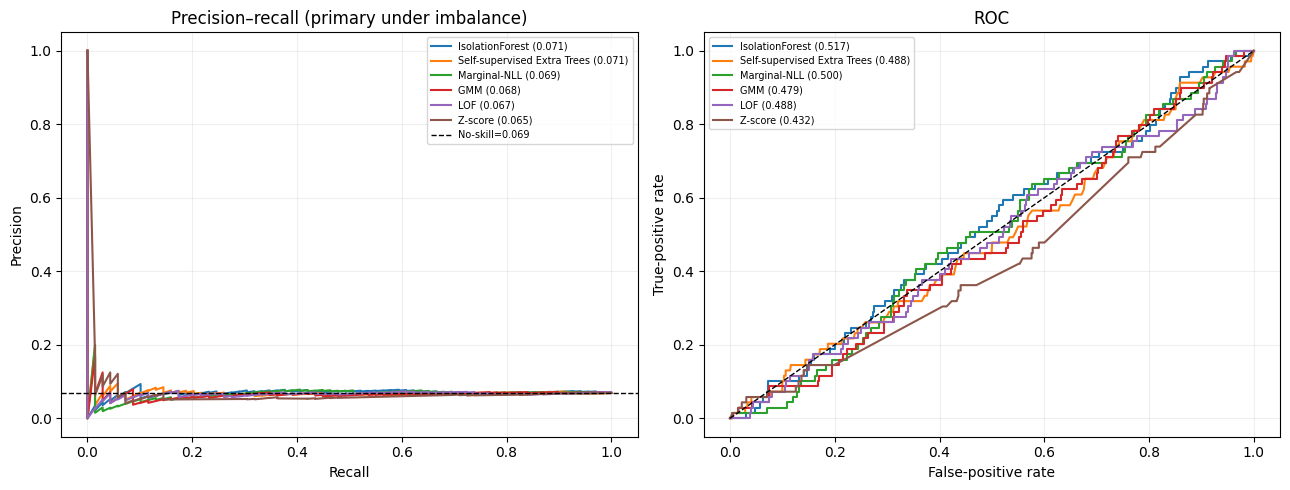

In [ ]:
#@title Figure 5 — Precision-recall and ROC curves
from sklearn.metrics import precision_recall_curve,roc_curve
fig,ax=plt.subplots(1,2,figsize=(13,5))
order=PRIMARY.Model.tolist()[:6]
for name in order:
    s=SCORES[name]; p,r,_=precision_recall_curve(y_test,s); fpr,tpr,_=roc_curve(y_test,s)
    ap=PRIMARY.set_index("Model").loc[name,"AUPRC"]; auc=PRIMARY.set_index("Model").loc[name,"AUROC"]
    ax[0].plot(r,p,label=f"{name} ({ap:.3f})"); ax[1].plot(fpr,tpr,label=f"{name} ({auc:.3f})")
ax[0].axhline(y_test.mean(),ls="--",lw=1,color="black",label=f"No-skill={y_test.mean():.3f}"); ax[0].set_xlabel("Recall"); ax[0].set_ylabel("Precision"); ax[0].set_title("Precision–recall (primary under imbalance)")
ax[1].plot([0,1],[0,1],ls="--",lw=1,color="black"); ax[1].set_xlabel("False-positive rate"); ax[1].set_ylabel("True-positive rate"); ax[1].set_title("ROC")
for a in ax: a.legend(fontsize=7); a.grid(alpha=.2)
fig.tight_layout(); show_figure(fig,"F05_roc_pr","Figure 5. Final-lockbox precision–recall and ROC curves; values in legends are AUPRC/AUROC.")


**Figure 6. MTT score separation on the untouched proposal endpoint.**

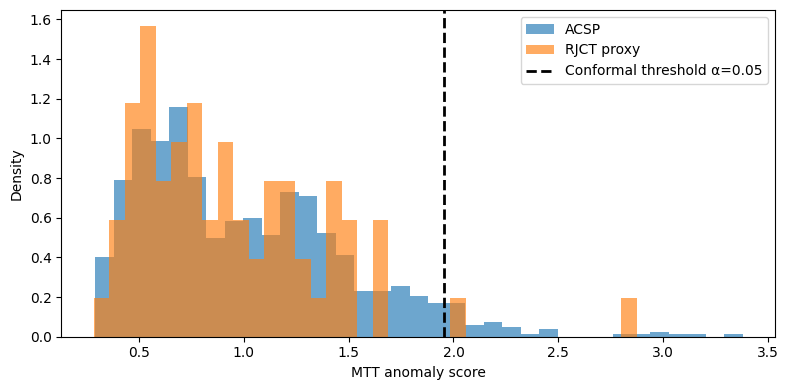

In [ ]:
#@title Figure 6 — MTT score distributions and conformal threshold
mtt=SCORES["MTT (2-seed ensemble)"]; th=THRESHOLDS["MTT (2-seed ensemble)"]
fig,ax=plt.subplots(figsize=(8,4)); ax.hist(mtt[y_test==0],bins=35,alpha=.65,density=True,label="ACSP"); ax.hist(mtt[y_test==1],bins=35,alpha=.65,density=True,label="RJCT proxy"); ax.axvline(th,ls="--",lw=2,color="black",label=f"Conformal threshold α={ALPHA_FPR:.2f}"); ax.set_xlabel("MTT anomaly score"); ax.set_ylabel("Density"); ax.legend(); fig.tight_layout(); show_figure(fig,"F06_mtt_scores","Figure 6. MTT score separation on the untouched proposal endpoint.")


## 10. Latency, throughput and model-size comparison

Latency is measured on the same final test set. For deep models, reported scoring time includes the method actually used for anomaly scoring. The MTT primary path therefore reflects deterministic leave-one-feature-out inference, while an additional fast 4-fold sensitivity row shows the speed/rigour trade-off.


**Table 15. Training time, inference latency, throughput and deep-model parameter counts.**

,Model,Fit_s,Score_s,ms_per_tx,tx_per_s,Parameters
2,Z-score,0.003267,0.000072,0.000072,1.379957e+07,NaN
8,Marginal-NLL,0.001741,0.001601,0.001601,6.247111e+05,NaN
6,PCA-recon,0.005173,0.004024,0.004024,2.484889e+05,NaN
7,GMM,0.135988,0.008172,0.004086,2.447302e+05,NaN
5,OCSVM,0.047670,0.023593,0.023593,4.238522e+04,NaN
4,LOF,0.081741,0.044901,0.044901,2.227121e+04,NaN
1,Denoising AE (2-seed),41.059259,0.140177,0.070088,1.426773e+04,679458.0
3,IsolationForest,3.300314,0.456065,0.228032,4.385341e+03,NaN
9,MTT seed42 (4-fold fast scoring),390.841251,1.407142,1.407142,7.106601e+02,212098.0
0,"MTT (2-seed ensemble, LOO)",782.045596,26.459970,13.229985,7.558588e+01,212098.0


**Figure 7. Final-test inference latency; MTT LOO trades speed for deterministic feature-conditional scoring.**

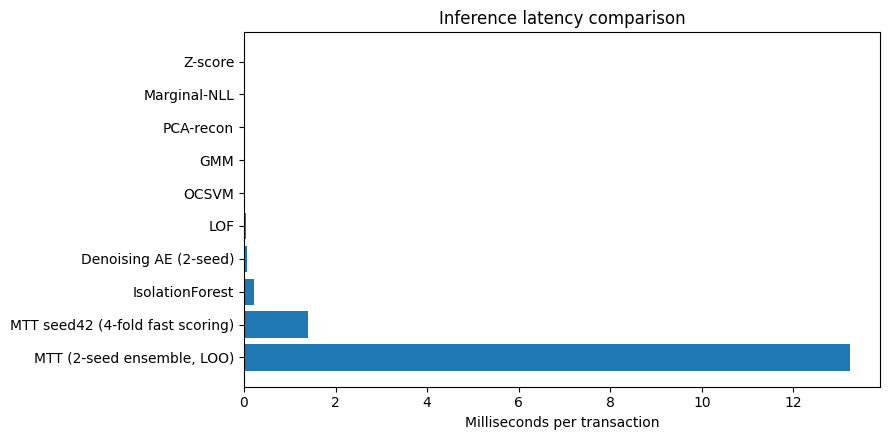

In [ ]:
#@title Table 15 + Figure 7 — Training and inference latency
lat=[]
# MTT actual two-seed ensemble compute
mfit=sum(r["info"]["fit_seconds"] for r in MTT_RUNS); mscore=sum(r["LOO_score_s"] if "LOO_score_s" in r else 0 for r in MTT_RUNS)
# info key above is stored in seed table rather than dict; reconstruct score time from seed table
mscore=float(MTT_SEED_TABLE["LOO_score_s"].sum())
lat.append({"Model":"MTT (2-seed ensemble, LOO)","Fit_s":mfit,"Score_s":mscore,"ms_per_tx":1000*mscore/(len(y_test)*len(SEEDS)),"tx_per_s":len(y_test)*len(SEEDS)/max(mscore,1e-9),"Parameters":MTT_RUNS[0] and M.count_parameters(MTT_RUNS[0]["model"])})
lat.append({"Model":"Denoising AE (2-seed)","Fit_s":sum(r["fit_s"] for r in DAE_RUNS),"Score_s":sum(r["score_s"] for r in DAE_RUNS),"ms_per_tx":1000*sum(r["score_s"] for r in DAE_RUNS)/(len(y_test)*len(SEEDS)),"tx_per_s":len(y_test)*len(SEEDS)/max(sum(r["score_s"] for r in DAE_RUNS),1e-9),"Parameters":DAE_RUNS[0]["params"]})
for name,o in CLASSICAL.items(): lat.append({"Model":name,"Fit_s":o["fit_s"],"Score_s":o["score_s"],"ms_per_tx":1000*o["score_s"]/(len(y_test)*(2 if name in ["IsolationForest","GMM"] else 1)),"tx_per_s":len(y_test)*(2 if name in ["IsolationForest","GMM"] else 1)/max(o["score_s"],1e-9),"Parameters":np.nan})
# Fast MTT feature-fold scoring sensitivity on seed 42
r=MTT_RUNS[0]; t=time.perf_counter(); _=M.fold_loss_matrix(r["model"],Xn_test,Xc_test,n_folds=4,device=DEVICE,seed=0); fast_s=time.perf_counter()-t
lat.append({"Model":"MTT seed42 (4-fold fast scoring)","Fit_s":r["info"]["fit_seconds"],"Score_s":fast_s,"ms_per_tx":1000*fast_s/len(y_test),"tx_per_s":len(y_test)/max(fast_s,1e-9),"Parameters":M.count_parameters(r["model"])})
LAT=pd.DataFrame(lat).sort_values("ms_per_tx"); show_table(LAT,"T15_latency","Table 15. Training time, inference latency, throughput and deep-model parameter counts.")
fig,ax=plt.subplots(figsize=(9,4.5)); q=LAT.sort_values("ms_per_tx",ascending=False); ax.barh(q.Model,q.ms_per_tx); ax.set_xlabel("Milliseconds per transaction"); ax.set_title("Inference latency comparison"); fig.tight_layout(); show_figure(fig,"F07_latency","Figure 7. Final-test inference latency; MTT LOO trades speed for deterministic feature-conditional scoring.")


## 11. Statistical inference on the final lockbox

The inferential unit is the **transaction**, not repeated folds. Each test transaction appears once. The MTT ensemble is compared with each baseline on the same lockbox observations using complementary tests:

1. paired stratified bootstrap for ΔAUPRC (primary);
2. paired DeLong for ΔAUROC;
3. paired score-swap permutation for AUPRC and AUROC;
4. exact McNemar for the split-conformal hardened decisions;
5. Holm family-wise correction across MTT-vs-baseline comparisons.


In [ ]:
#@title Table 16 — Bootstrap confidence intervals for every model
ci_rows=[]
for i,(name,s) in enumerate(SCORES.items()):
    ap=S.stratified_bootstrap_metric(y_test,s,"AUPRC",CFG["n_boot"],SEEDS[0]+i); au=S.stratified_bootstrap_metric(y_test,s,"AUROC",CFG["n_boot"],SEEDS[0]+100+i)
    ci_rows.append({"Model":name,"AUPRC":ap["estimate"],"AUPRC_CI":f"[{ap['CI_low']:.4f}, {ap['CI_high']:.4f}]","AUROC":au["estimate"],"AUROC_CI":f"[{au['CI_low']:.4f}, {au['CI_high']:.4f}]"})
show_table(pd.DataFrame(ci_rows).sort_values("AUPRC",ascending=False),"T16_metric_ci","Table 16. Transaction-level stratified-bootstrap 95% confidence intervals.")


**Table 16. Transaction-level stratified-bootstrap 95% confidence intervals.**

,Model,AUPRC,AUPRC_CI,AUROC,AUROC_CI
4,IsolationForest,0.071411,"[0.0612, 0.0917]",0.517303,"[0.4487, 0.5886]"
2,Self-supervised Extra Trees,0.071279,"[0.0592, 0.1058]",0.487850,"[0.4156, 0.5575]"
9,Marginal-NLL,0.068596,"[0.0594, 0.0988]",0.499992,"[0.4332, 0.5691]"
8,GMM,0.067709,"[0.0577, 0.0990]",0.479195,"[0.4121, 0.5468]"
5,LOF,0.066961,"[0.0582, 0.0861]",0.487508,"[0.4157, 0.5591]"
3,Z-score,0.064785,"[0.0545, 0.0992]",0.431560,"[0.3621, 0.5037]"
1,Denoising AE (2-seed),0.064594,"[0.0575, 0.0847]",0.486402,"[0.4254, 0.5476]"
0,MTT (2-seed ensemble),0.063513,"[0.0554, 0.0908]",0.465169,"[0.3988, 0.5329]"
6,OCSVM,0.063016,"[0.0548, 0.0800]",0.463472,"[0.3988, 0.5297]"
7,PCA-recon,0.059901,"[0.0523, 0.0829]",0.428976,"[0.3627, 0.4967]"


In [ ]:
#@title Table 17 — MTT vs every baseline: paired significance tests + Holm correction
mname="MTT (2-seed ensemble)"; ma=SCORES[mname]; pred_m=(ma>=THRESHOLDS[mname]).astype(int); rows=[]
for i,(name,sb) in enumerate(SCORES.items()):
    if name==mname: continue
    b=S.paired_bootstrap_delta(y_test,ma,sb,"AUPRC",CFG["n_boot"],SEEDS[0]+i)
    d=S.delong_test(y_test,ma,sb); pp=S.paired_score_swap_test(y_test,ma,sb,"AUPRC",CFG["n_perm"],SEEDS[0]+20+i); pr=S.paired_score_swap_test(y_test,ma,sb,"AUROC",CFG["n_perm"],SEEDS[0]+40+i)
    pred_b=(sb>=THRESHOLDS[name]).astype(int); mc=S.mcnemar_test(y_test,pred_m,pred_b)
    rows.append({"Baseline":name,**b,"delta_AUROC":d["delta_AUROC"],"DeLong_p":d["p_value"],"AUROC_CI":f"[{d['CI_low']:.4f},{d['CI_high']:.4f}]","AUPRC_perm_p":pp["permutation_p"],"AUROC_perm_p":pr["permutation_p"],**mc})
SIG=pd.DataFrame(rows); SIG=S.holm_adjust(SIG,["bootstrap_p","DeLong_p","AUPRC_perm_p","AUROC_perm_p","McNemar_p"])
show_table(SIG.sort_values("delta_AUPRC",ascending=False),"T17_significance","Table 17. Paired MTT-versus-baseline inference on independent final-lockbox transactions, with Holm correction.")


**Table 17. Paired MTT-versus-baseline inference on independent final-lockbox transactions, with Holm correction.**

,Baseline,delta_AUPRC,CI_low,CI_high,bootstrap_p,delta_AUROC,DeLong_p,AUROC_CI,AUPRC_perm_p,AUROC_perm_p,discordant_A_correct,discordant_B_correct,McNemar_p,bootstrap_p_Holm,DeLong_p_Holm,AUPRC_perm_p_Holm,AUROC_perm_p_Holm,McNemar_p_Holm
6,PCA-recon,0.003612,-0.016273,0.024855,0.651333,0.036193,0.299021,"[-0.0321,0.1045]",0.742052,0.525495,23,38,0.072177,1.0,1.000000,1.0,1.0,0.433065
5,OCSVM,0.000496,-0.013739,0.020316,0.905333,0.001697,0.961294,"[-0.0668,0.0702]",0.972805,0.980804,58,26,0.000628,1.0,1.000000,1.0,1.0,0.005652
0,Denoising AE (2-seed),-0.001081,-0.012759,0.013031,0.894667,-0.021233,0.533259,"[-0.0880,0.0456]",0.832633,0.520096,26,33,0.434993,1.0,1.000000,1.0,1.0,1.000000
2,Z-score,-0.001273,-0.018582,0.008727,0.803333,0.033609,0.253299,"[-0.0241,0.0913]",0.883223,0.510898,50,31,0.044829,1.0,1.000000,1.0,1.0,0.313800
4,LOF,-0.003448,-0.020231,0.020699,0.717333,-0.022338,0.576118,"[-0.1007,0.0560]",0.730254,0.616077,65,35,0.003518,1.0,1.000000,1.0,1.0,0.028141
7,GMM,-0.004196,-0.022811,0.009911,0.532000,-0.014026,0.691025,"[-0.0832,0.0551]",0.714657,0.828034,58,41,0.107352,1.0,1.000000,1.0,1.0,0.536758
8,Marginal-NLL,-0.005083,-0.015542,0.003042,0.202667,-0.034823,0.135583,"[-0.0806,0.0109]",0.711058,0.596681,15,23,0.255875,1.0,1.000000,1.0,1.0,1.000000
1,Self-supervised Extra Trees,-0.007767,-0.041472,0.018944,0.524667,-0.022681,0.637249,"[-0.1170,0.0716]",0.525695,0.730454,57,48,0.435114,1.0,1.000000,1.0,1.0,1.000000
3,IsolationForest,-0.007898,-0.024591,0.014767,0.390000,-0.052133,0.081691,"[-0.1108,0.0066]",0.503699,0.325335,31,27,0.694004,1.0,0.735223,1.0,1.0,1.000000


## 12. Reconstruction quality required by the proposal

These metrics assess the self-supervised pretext task on accepted REF traffic and are distinct from anomaly-detection performance. Numerical fields are evaluated after reversing the robust scale; categorical fields report NLL, Top-1 and Top-3 accuracy.


In [ ]:
#@title Tables 18–19 — Numerical and categorical reconstruction metrics
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
rep=MTT_RUNS[0]; npred,cnll,hit1,hit3=M.loo_reconstruction_outputs(rep["model"],Xn_ref,Xc_ref,device=DEVICE)
true_num=ENC.inverse_numeric(Xn_ref); pred_num=ENC.inverse_numeric(npred)
num_rows=[]
for j,c in enumerate(D.NUMERIC_FEATURES):
    yt=true_num[:,j]; yp=pred_num[:,j]; mae=mean_absolute_error(yt,yp); mse=mean_squared_error(yt,yp); rmse=np.sqrt(mse); smape=np.mean(2*np.abs(yp-yt)/(np.abs(yt)+np.abs(yp)+1e-8)); r2=r2_score(yt,yp)
    num_rows.append({"Feature":c,"MAE":mae,"MSE":mse,"RMSE":rmse,"SMAPE":smape,"R2":r2})
# Proposal-relevant amount reconstruction in original currency units
j=D.NUMERIC_FEATURES.index("log_amount"); amt_true=np.expm1(true_num[:,j]); amt_pred=np.maximum(0,np.expm1(pred_num[:,j]));
num_rows.append({"Feature":"InstdAmt (back-transformed)","MAE":mean_absolute_error(amt_true,amt_pred),"MSE":mean_squared_error(amt_true,amt_pred),"RMSE":np.sqrt(mean_squared_error(amt_true,amt_pred)),"SMAPE":np.mean(2*np.abs(amt_pred-amt_true)/(np.abs(amt_true)+np.abs(amt_pred)+1e-8)),"R2":r2_score(amt_true,amt_pred)})
show_table(pd.DataFrame(num_rows),"T18_numeric_reconstruction","Table 18. Numerical leave-one-feature-out reconstruction quality on accepted REF traffic.")
cat_rows=[]
for j,c in enumerate(D.CATEGORICAL_FEATURES): cat_rows.append({"Feature":c,"NLL":cnll[:,j].mean(),"Top1":hit1[:,j].mean(),"Top3":hit3[:,j].mean(),"Cardinality":CAT_SIZES[j]})
show_table(pd.DataFrame(cat_rows),"T19_categorical_reconstruction","Table 19. Categorical reconstruction NLL and Top-k accuracy on accepted REF traffic.")


**Table 18. Numerical leave-one-feature-out reconstruction quality on accepted REF traffic.**

,Feature,MAE,MSE,RMSE,SMAPE,R2
0,log_amount,0.582209,5.295950e-01,0.727733,0.084024,-0.016421
1,amt_cents,24.617717,8.198009e+02,28.632165,0.585082,-0.016419
2,hour_sin,0.403472,2.052531e-01,0.453049,1.245555,0.330299
3,hour_cos,0.098316,1.641954e-02,0.128139,0.148657,0.580803
4,dow_sin,0.547924,4.227031e-01,0.650156,1.895767,-0.006935
5,dow_cos,0.839810,7.672456e-01,0.875926,1.927224,-9.696105
6,is_weekend,0.364628,1.864204e-01,0.431764,1.779377,0.049920
7,settle_lag_days,0.348621,1.807654e-01,0.425165,1.834813,-0.014793
8,vel_agentpair_60s,0.038017,1.470745e-02,0.121274,1.999996,-0.166982
9,vel_sameamt_300s,0.042611,2.600135e-03,0.050992,1.999997,0.000000


**Table 19. Categorical reconstruction NLL and Top-k accuracy on accepted REF traffic.**

,Feature,NLL,Top1,Top3,Cardinality
0,Currency,1.126749,0.334043,1.000000,4
1,DbtrAgtBIC,1.556294,0.278723,0.614894,14
2,CdtrAgtBIC,1.021393,0.461702,0.857447,15
3,DbtrCountry,0.019223,1.000000,1.000000,5
4,CdtrCountry,0.022529,1.000000,1.000000,6
5,PurposeCode,2.238586,0.091489,0.321277,10
6,dbtr_bic_ctry,0.013026,1.000000,1.000000,5
7,cdtr_bic_ctry,0.025268,1.000000,1.000000,6


## 13. Two-seed stability and operational alert-budget analysis

The seed table shows whether a claimed gain is larger than neural initialisation variability. Operational metrics complement AUROC: a payment-monitoring team typically reviews a bounded alert queue, so precision/recall at 1% and 5% alert budgets are reported explicitly.


**Table 20. MTT stability across the two pre-specified random seeds.**

,Seed,AUROC,AUPRC,AUPRC_lift,Precision@1%,Recall@1%,F1@1%,Lift@1%,Precision@5%,Recall@5%,...,Specificity,FPR,MCC,TP,FP,TN,FN,Fit_s,LOO_score_s,Parameters
0,42,0.450505,0.060762,0.880612,0.1,0.014493,0.025316,1.449275,0.02,0.014493,...,0.957035,0.042965,-0.036393,1,40,891,68,390.841251,13.128421,212098
1,2026,0.493812,0.068750,0.996379,0.1,0.014493,0.025316,1.449275,0.06,0.043478,...,0.960258,0.039742,-0.033471,1,37,894,68,391.204345,13.331549,212098


**Figure 8. Seed sensitivity of the proposed MTT.**

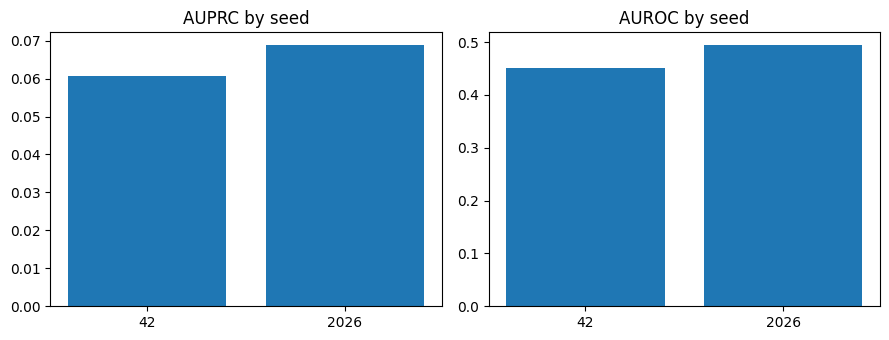

In [ ]:
#@title Table 20 + Figure 8 — MTT seed stability
show_table(MTT_SEED_TABLE,"T20_seed_stability","Table 20. MTT stability across the two pre-specified random seeds.")
fig,ax=plt.subplots(1,2,figsize=(9,3.5)); ax[0].bar(MTT_SEED_TABLE.Seed.astype(str),MTT_SEED_TABLE.AUPRC); ax[0].set_title("AUPRC by seed"); ax[1].bar(MTT_SEED_TABLE.Seed.astype(str),MTT_SEED_TABLE.AUROC); ax[1].set_title("AUROC by seed"); fig.tight_layout(); show_figure(fig,"F08_seed_stability","Figure 8. Seed sensitivity of the proposed MTT.")


In [ ]:
#@title Table 21 — Hypothetical operational-cost sensitivity (not a claim of fraud cost)
rows=[]
for ratio in [5,10,25,50]:
    for _,r in PRIMARY.iterrows():
        cost=ratio*r.FN+r.FP
        rows.append({"FN:FP cost ratio":f"{ratio}:1","Model":r.Model,"Normalised_cost":cost/len(y_test),"FN":r.FN,"FP":r.FP})
show_table(pd.DataFrame(rows).sort_values(["FN:FP cost ratio","Normalised_cost"]),"T21_cost_sensitivity","Table 21. Scenario analysis for review/missed-exception trade-offs; these are hypothetical operational weights, not monetary fraud-loss estimates.")


**Table 21. Scenario analysis for review/missed-exception trade-offs; these are hypothetical operational weights, not monetary fraud-loss estimates.**

,FN:FP cost ratio,Model,Normalised_cost,FN,FP
19,10:1,PCA-recon,0.699,67,29
11,10:1,Self-supervised Extra Trees,0.705,65,55
15,10:1,Z-score,0.706,64,66
16,10:1,Denoising AE (2-seed),0.707,67,37
17,10:1,MTT (2-seed ensemble),0.714,67,44
12,10:1,Marginal-NLL,0.715,68,35
14,10:1,LOF,0.717,64,77
10,10:1,IsolationForest,0.718,67,48
13,10:1,GMM,0.722,66,62
18,10:1,OCSVM,0.728,65,78


## 14. Ablation ladder — what actually makes the MTT work?

Ablations use the same frozen chronological TEST lockbox and average two seeds when retraining is required. They do not re-tune on TEST labels. A2 is a genuine plain autoencoder objective (unmasked input, full reconstruction loss), correcting the common implementation error of calling 100% masking an “autoencoder”. A3 is a joint MLP without attention and is parameter-matched as closely as possible to the Transformer.


In [ ]:
#@title Run 12-arm ablation ladder
ABL_SCORES={}; ABL_META=[]
if RUN_ABLATIONS:
    ABL_SCORES["A1 full MTT"]=SCORES["MTT (2-seed ensemble)"]
    # no-retrain score ablations from already-fitted MTT seed models
    def score_from_loss_variant(method):
        vals=[]
        for r in MTT_RUNS: vals.append(r["scorer"].score(r["L_test"],method))
        return np.mean(vals,axis=0)
    ABL_SCORES["A4 z-loss no empirical tail"] = np.mean([((r["L_test"]-r["L_ref"].mean(0))/np.maximum(r["L_ref"].std(0),1e-8)).mean(1) for r in MTT_RUNS],axis=0)
    ABL_SCORES["A5 no semantic group balance"] = score_from_loss_variant("feature_mean")
    ABL_SCORES["A6 max-group aggregation"] = score_from_loss_variant("max_group")
    ABL_SCORES["A7 covariance only"] = score_from_loss_variant("mahal")
    # fast feature-fold inference
    vv=[]
    for r in MTT_RUNS:
        L=M.fold_loss_matrix(r["model"],Xn_test,Xc_test,n_folds=4,device=DEVICE,seed=0); vv.append(r["scorer"].score(L,str(BEST_MTT["score_method"])))
    ABL_SCORES["A8 fast 4-fold inference"] = np.mean(vv,axis=0)

    def train_variant(label,p_update=None,objective="masked",encoder="transformer",param_match=False,train=True,auto_score=False):
        vals=[]; pars=[]
        for seed in SEEDS:
            p={**BEST_MTT,**(p_update or {})}; p["epochs"]=CFG["ablation_epochs"]
            if not train:
                model=E.build_model(Xn_dev.shape[1],CAT_SIZES,p); info={"fit_seconds":0}
            else:
                if param_match:
                    target=E.build_model(Xn_dev.shape[1],CAT_SIZES,p); targetp=M.count_parameters(target); match=M.matched_mlp_hidden(Xn_dev.shape[1],CAT_SIZES,targetp,int(p["d_token"]),float(p.get("dropout",.1))); model,info=E.fit_mtt(Xn_dev,Xc_dev,CAT_SIZES,p,seed,DEVICE,objective=objective,encoder="joint_mlp",mlp_hidden=match["hidden"]); pars.append((targetp,M.count_parameters(model),match["relative_gap"]))
                elif objective=="masked": model,info=E.fit_mtt(Xn_dev,Xc_dev,CAT_SIZES,p,seed,DEVICE,objective=objective)
                else:
                    model=E.build_model(Xn_dev.shape[1],CAT_SIZES,p,encoder=encoder); model,info=M.train_reconstructor(model,Xn_dev,Xc_dev,objective=objective,mask_ratio=float(p.get("mask_ratio",.35)),epochs=int(p["epochs"]),batch_size=256,lr=float(p.get("lr",8e-4)),weight_decay=float(p.get("weight_decay",1e-5)),device=DEVICE,seed=seed)
            if objective=="autoencoder": Lr=M.autoencoder_loss_matrix(model,Xn_ref,Xc_ref,DEVICE); Lt=M.autoencoder_loss_matrix(model,Xn_test,Xc_test,DEVICE)
            else: Lr=M.loo_loss_matrix(model,Xn_ref,Xc_ref,DEVICE); Lt=M.loo_loss_matrix(model,Xn_test,Xc_test,DEVICE)
            sc=M.ReconScoreModel(GROUPS).fit(Lr); vals.append(sc.score(Lt,str(BEST_MTT["score_method"])))
        ABL_SCORES[label]=np.mean(vals,axis=0); ABL_META.append({"Arm":label,"Parameter_match":repr(pars)})

    train_variant("A0 random init / no SSL",train=False)
    train_variant("A2 plain autoencoder objective",objective="autoencoder")
    train_variant("A3 attention-free matched MLP",param_match=True)
    train_variant("A9 mask ratio 0.15",{"mask_ratio":.15})
    train_variant("A10 mask ratio 0.65",{"mask_ratio":.65})
    train_variant("A11 depth 1",{"n_layers":1})

    abrows=[]
    for arm,s in ABL_SCORES.items(): abrows.append({"Arm":arm,**S.ranking_metrics(y_test,s)})
    ABL=pd.DataFrame(abrows).sort_values("AUPRC",ascending=False)
    # paired bootstrap delta vs full; descriptive/causal component analysis, not model selection
    sigrows=[]; full=ABL_SCORES["A1 full MTT"]
    for i,(arm,s) in enumerate(ABL_SCORES.items()):
        if arm=="A1 full MTT": continue
        d=S.paired_bootstrap_delta(y_test,full,s,"AUPRC",min(CFG["n_boot"],1500),SEEDS[0]+300+i); sigrows.append({"Arm":arm,**d})
    ABLSIG=pd.DataFrame(sigrows); ABLSIG=S.holm_adjust(ABLSIG,["bootstrap_p"])
    show_table(ABL,"T22_ablation_results","Table 22. Twelve-arm ablation ladder on the primary proposal endpoint.")
    show_table(ABLSIG,"T23_ablation_significance","Table 23. Paired ΔAUPRC of the full MTT versus each ablation, Holm adjusted.")
    if ABL_META: show_table(pd.DataFrame(ABL_META),"T24_ablation_params","Table 24. Parameter-matching audit for architecture ablations.")
    fig,ax=plt.subplots(figsize=(9,5)); q=ABL.sort_values("AUPRC"); ax.barh(q.Arm,q.AUPRC); ax.axvline(y_test.mean(),ls="--",color="black",lw=1,label="no-skill prevalence"); ax.set_xlabel("AUPRC"); ax.legend(); fig.tight_layout(); show_figure(fig,"F09_ablation","Figure 9. Ablation ladder: contribution of training, attention, masking and scoring design.")
else:
    print("Ablations disabled in configuration.")


Ablations disabled in configuration.


## 15. Controlled ISO-dependency benchmark

**Moved to section 8b in v5** so it runs before the (slow) ablations and cannot be skipped by a timeout.


_Controlled benchmark cell moved to section 8b._

## 16. Field-level interpretability and top alerts

Every MTT alert can be decomposed into empirical reconstruction-surprise contributions. This supports the proposal's requirement to identify which message fields drive anomaly scores and provides a transaction-monitoring style audit trail.


**Table 27. Which ex-ante fields contribute most strongly to MTT reconstruction surprise for rejected proxy outcomes?**

,Feature,Normal_median,RJCT_median,Rank_biserial,p_value,p_Holm
14,CdtrCountry,0.636366,0.946553,0.115226,0.109914,1.0
17,cdtr_bic_ctry,0.722779,0.907280,0.113109,0.116600,1.0
6,is_weekend,0.619823,0.699975,0.089432,0.214725,1.0
10,Currency,0.708809,0.832062,0.084295,0.242243,1.0
4,dow_sin,1.167233,1.309031,0.079080,0.271044,1.0
0,log_amount,0.689082,0.803202,0.048164,0.504087,1.0
16,dbtr_bic_ctry,0.569697,0.524167,-0.002039,0.977599,1.0
2,hour_sin,0.743302,0.758963,-0.005682,0.937333,1.0
13,DbtrCountry,0.587060,0.510787,-0.012998,0.857043,1.0
3,hour_cos,0.647186,0.645576,-0.032379,0.653393,1.0


**Table 28. Ten highest-scoring final-lockbox payments and their leading field-level reconstruction drivers.**

,Rank,MTT_score,TxSts,RejectionReason,Amount,Route,Driver_1,Driver_2,Driver_3
0,1,3.377714,ACSP,NaN,1805.53,DE->GB,vel_agentpair_60s,PurposeCode,CdtrAgtBIC
1,2,3.176293,ACSP,NaN,1314.16,DE->GB,vel_agentpair_60s,dow_sin,CdtrAgtBIC
2,3,3.079187,ACSP,NaN,492.11,FR->DE,hour_cos,PurposeCode,dow_sin
3,4,2.943037,ACSP,NaN,355.68,GB->US,vel_agentpair_60s,settle_lag_days,CdtrCountry
4,5,2.940059,ACSP,NaN,388.77,GB->FR,vel_agentpair_60s,DbtrAgtBIC,log_amount
5,6,2.891223,ACSP,NaN,1597.24,GB->FR,vel_agentpair_60s,dow_sin,DbtrAgtBIC
6,7,2.872525,RJCT,AM05,1497.70,GB->US,vel_agentpair_60s,CdtrCountry,Currency
7,8,2.823940,ACSP,NaN,586.05,FR->DE,hour_cos,dow_sin,amt_cents
8,9,2.475142,ACSP,NaN,459.30,NL->GB,PurposeCode,DbtrCountry,dbtr_bic_ctry
9,10,2.465906,ACSP,NaN,731.99,NL->GB,PurposeCode,hour_sin,dbtr_bic_ctry


**Figure 11. Mean field-level MTT reconstruction surprise by proxy outcome.**

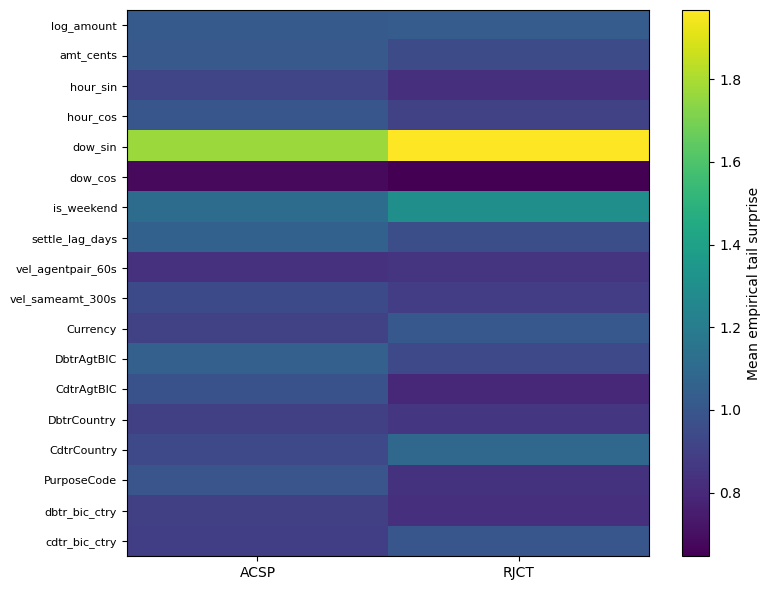

In [ ]:
#@title Tables 27–28 + Figure 11 — Field-level reconstruction surprise
names=D.NUMERIC_FEATURES+D.CATEGORICAL_FEATURES
FS=np.mean([r["scorer"].feature_surprise(r["L_test"]) for r in MTT_RUNS],axis=0)
rows=[]
from scipy.stats import mannwhitneyu
for j,nm in enumerate(names):
    a=FS[y_test==0,j]; b=FS[y_test==1,j]; u,p=mannwhitneyu(b,a,alternative="two-sided"); rb=2*u/(len(a)*len(b))-1
    rows.append({"Feature":nm,"Normal_median":np.median(a),"RJCT_median":np.median(b),"Rank_biserial":rb,"p_value":p})
ATTR=pd.DataFrame(rows); ATTR["p_Holm"]=statsmodels.stats.multitest.multipletests(ATTR.p_value,method="holm")[1]
show_table(ATTR.sort_values("Rank_biserial",ascending=False),"T27_feature_attribution","Table 27. Which ex-ante fields contribute most strongly to MTT reconstruction surprise for rejected proxy outcomes?")

top=np.argsort(-SCORES["MTT (2-seed ensemble)"])[:10]; alert_rows=[]
for rank,i in enumerate(top,1):
    drivers=np.argsort(-FS[i])[:3]
    raw=df.iloc[test_idx[i]]
    alert_rows.append({"Rank":rank,"MTT_score":SCORES["MTT (2-seed ensemble)"][i],"TxSts":raw.TxSts,"RejectionReason":raw.RejectionReason,"Amount":raw.InstdAmt,
                       "Route":f"{raw.DbtrCountry}->{raw.CdtrCountry}","Driver_1":names[drivers[0]],"Driver_2":names[drivers[1]],"Driver_3":names[drivers[2]]})
show_table(pd.DataFrame(alert_rows),"T28_top_alerts","Table 28. Ten highest-scoring final-lockbox payments and their leading field-level reconstruction drivers.")
fig,ax=plt.subplots(figsize=(8,6)); z=pd.DataFrame(FS,columns=names).assign(Status=np.where(y_test==1,"RJCT","ACSP")).groupby("Status").mean().T; im=ax.imshow(z.to_numpy(),aspect="auto",cmap="viridis"); ax.set_yticks(range(len(names))); ax.set_yticklabels(names,fontsize=8); ax.set_xticks([0,1]); ax.set_xticklabels(z.columns); fig.colorbar(im,ax=ax,label="Mean empirical tail surprise"); fig.tight_layout(); show_figure(fig,"F11_feature_surprise","Figure 11. Mean field-level MTT reconstruction surprise by proxy outcome.")


## 17. Publication-ready conclusion logic

This cell deliberately refuses to manufacture a conclusion. It checks whether the MTT is numerically best and whether its AUPRC improvement over the strongest baseline is statistically supported after multiplicity correction.


In [ ]:
#@title Automated bounded interpretation of both endpoints
m=PRIMARY.set_index("Model").loc["MTT (2-seed ensemble)"]
best_other=PRIMARY[PRIMARY.Model!="MTT (2-seed ensemble)"].iloc[0]
print("EXTERNAL TxSts PROXY ENDPOINT")
print(f"MTT AUPRC={m.AUPRC:.4f}, AUROC={m.AUROC:.4f}, F1={m.F1:.4f}")
print(f"Strongest comparator by AUPRC: {best_other.Model}, AUPRC={best_other.AUPRC:.4f}")
print("This endpoint measures association with operational rejection, not confirmed fraud.")
if m.AUROC<.55 and m.AUPRC<2*y_test.mean():
    print("Finding: the allowed ex-ante fields contain little recoverable TxSts signal; further TEST-driven tuning is not justified.")

if RUN_CONTROLLED_BENCHMARK:
    print("\nCONTROLLED STRUCTURAL-ANOMALY ENDPOINT")
    print(CTRL_SUMMARY[["Model","AUPRC","AUROC","Precision@5%","Recall@5%"]].head(10).to_string(index=False))
    best_ctrl=CTRL_SUMMARY.iloc[0]
    print(f"Finding: {best_ctrl.Model} is strongest on the balanced controlled lockbox (AUPRC={best_ctrl.AUPRC:.4f}, AUROC={best_ctrl.AUROC:.4f}).")
    print("This supports detection of the specified ISO violations only; it does not establish real-fraud performance.")
    print("\nMTT variants vs strongest non-MTT comparator (controlled lockbox, AUPRC / AUROC):")
    _non=CTRL_SUMMARY[~CTRL_SUMMARY.Model.str.startswith("MTT")].iloc[0]
    for _,_r in CTRL_SUMMARY[CTRL_SUMMARY.Model.str.startswith("MTT")].iterrows():
        print(f"  {_r.Model:28s} AUPRC={_r.AUPRC:.4f} AUROC={_r.AUROC:.4f}   (strongest non-MTT: {_non.Model} AUPRC={_non.AUPRC:.4f} AUROC={_non.AUROC:.4f})")
    _a6=FAM[(FAM.Family=="A6_currency_null")&(FAM.Model.str.startswith("MTT"))]
    print("Null-control (A6) AUROC for MTT variants:",{r.Model:round(r.AUROC,3) for r in _a6.itertuples()},"-> should be ~0.5")


EXTERNAL TxSts PROXY ENDPOINT
MTT AUPRC=0.0635, AUROC=0.4652, F1=0.0348
Strongest comparator by AUPRC: IsolationForest, AUPRC=0.0714
This endpoint measures association with operational rejection, not confirmed fraud.
Finding: the allowed ex-ante fields contain little recoverable TxSts signal; further TEST-driven tuning is not justified.

CONTROLLED STRUCTURAL-ANOMALY ENDPOINT
                      Model    AUPRC    AUROC  Precision@5%  Recall@5%
Self-supervised Extra Trees 0.937541 0.909065           1.0   0.099893
    MTT + learned-field max 0.900252 0.860935           1.0   0.099893
      Denoising AE (2-seed) 0.896128 0.848552           1.0   0.099893
                        LOF 0.892528 0.848962           1.0   0.099893
                        GMM 0.862797 0.826994           1.0   0.099893
      MTT (2-seed ensemble) 0.861161 0.816063           1.0   0.099893
     MTT twin-joint masking 0.856676 0.807463           1.0   0.099893
    MTT + learned-field sum 0.848714 0.811807        

## 18. Export: tables, figures, models and manifest

All tables are exported as CSV and LaTeX, figures as PNG and vector PDF, deep models as PyTorch state dictionaries, and the run configuration/data hash as JSON. The complete package is zipped for dissertation and journal archiving.


In [ ]:
#@title Export reproducibility package
manifest={
    "dataset_sha256":file_hash,"rows":len(df),"proposal_endpoint":"TxSts proxy: RJCT=anomaly, ACSP=normal (evaluation only)",
    "excluded_fields":D.EX_POST_FIELDS+D.IDENTIFIERS,"preset":PRESET,"seeds":SEEDS,"alpha_fpr":ALPHA_FPR,"device":DEVICE,
    "best_mtt":BEST_MTT,"best_dae":BEST_DAE,"best_baselines":BEST_BASE,
    "ctgan_used":False,"self_supervised_reference":SS_BEST,
    "split":split_tbl.astype(str).to_dict(orient="records"),
    "versions":{"python":platform.python_version(),"numpy":np.__version__,"pandas":pd.__version__,"torch":torch.__version__,"sklearn":sklearn.__version__,"scipy":scipy.__version__},
}
(OUT/"manifest.json").write_text(json.dumps(manifest,indent=2,default=str))
# Export final score vectors for exact paired re-analysis
pd.DataFrame({"row_index":test_idx,"y_proxy":y_test,**{k:v for k,v in SCORES.items()}}).to_csv(OUT/"final_lockbox_scores.csv",index=False)
zip_path=Path("ISO20022_MTT_V3_results.zip")
with zipfile.ZipFile(zip_path,"w",zipfile.ZIP_DEFLATED) as z:
    for p in OUT.rglob("*"):
        if p.is_file(): z.write(p,p.as_posix())
print("Created",zip_path,"with",len(TABLES),"tables and",len(FIGURES),"figures")
try:
    from google.colab import files
    print("Use files.download('ISO20022_MTT_V3_results.zip') if you want the archive locally.")
except Exception: pass


Created ISO20022_MTT_V3_results.zip with 32 tables and 10 figures
Use files.download('ISO20022_MTT_V3_results.zip') if you want the archive locally.
